<a href="https://colab.research.google.com/github/apsarak26/capstone_project_CS5998/blob/main/FAERS_Preprocessing_EDA_and_AEOLUS_Integration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [88]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

base_dir = "/content/drive/MyDrive/Capstone"

faers_dir = os.path.join(base_dir, "ascii")
output_dir = os.path.join(base_dir, "faers_processed")

os.makedirs(output_dir, exist_ok=True)

print("Raw data folder exists:", os.path.exists(faers_dir))
print("Output folder exists:", os.path.exists(output_dir))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw data folder exists: True
Output folder exists: True


In [ ]:
file_details = []

for file_name in sorted(os.listdir(faers_dir)):
    file_path = os.path.join(faers_dir, file_name)

    if os.path.isfile(file_path):
        file_details.append({
            "file_name": file_name,
            "size_mb": round(
                os.path.getsize(file_path) / (1024 ** 2), 2
            )
        })

faers_files_df = pd.DataFrame(file_details)

display(faers_files_df)

print("Total files:", len(faers_files_df))

,file_name,size_mb
0,ASC_NTS.doc,0.17
1,DEMO14Q1.txt,31.13
2,DRUG14Q1.txt,62.60
3,INDI14Q1.txt,24.37
4,OUTC14Q1.txt,3.48
5,REAC14Q1.txt,25.10
6,RPSR14Q1.txt,0.81
7,THER14Q1.txt,10.85
8,demo14q1.pdf,0.08
9,drug14q1.pdf,0.22


Total files: 15


In [ ]:
for file_name in sorted(os.listdir(faers_dir)):

    if file_name.lower().endswith(".txt"):

        file_path = os.path.join(faers_dir, file_name)

        with open(file_path, "r", encoding="latin-1") as file:
            header = file.readline().strip()

        columns = header.split("$")

        print("\nFile:", file_name)
        print("Number of columns:", len(columns))
        print("Columns:", columns)
        print("-" * 70)


File: DEMO14Q1.txt
Number of columns: 22
Columns: ['primaryid', 'caseid', 'caseversion', 'i_f_code', 'event_dt', 'mfr_dt', 'init_fda_dt', 'fda_dt', 'rept_cod', 'mfr_num', 'mfr_sndr', 'age', 'age_cod', 'gndr_cod', 'e_sub', 'wt', 'wt_cod', 'rept_dt', 'to_mfr', 'occp_cod', 'reporter_country', 'occr_country']
----------------------------------------------------------------------

File: DRUG14Q1.txt
Number of columns: 19
Columns: ['primaryid', 'caseid', 'drug_seq', 'role_cod', 'drugname', 'val_vbm', 'route', 'dose_vbm', 'cum_dose_chr', 'cum_dose_unit', 'dechal', 'rechal', 'lot_num', 'exp_dt', 'nda_num', 'dose_amt', 'dose_unit', 'dose_form', 'dose_freq']
----------------------------------------------------------------------

File: INDI14Q1.txt
Number of columns: 4
Columns: ['primaryid', 'caseid', 'indi_drug_seq', 'indi_pt']
----------------------------------------------------------------------

File: OUTC14Q1.txt
Number of columns: 3
Columns: ['primaryid', 'caseid', 'outc_cod']
------------

exploring the DEMO table

In [ ]:
demo_df = pd.read_csv(
    os.path.join(faers_dir, "DEMO14Q1.txt"),
    sep="$",
    encoding="latin-1",
    dtype=str
)

print("Dataset shape:", demo_df.shape)

display(demo_df.head())

Dataset shape: (260057, 22)


,primaryid,caseid,caseversion,i_f_code,event_dt,mfr_dt,init_fda_dt,fda_dt,rept_cod,mfr_num,...,age_cod,gndr_cod,e_sub,wt,wt_cod,rept_dt,to_mfr,occp_cod,reporter_country,occr_country
0,100033001,10003300,1,I,NaN,20131015,20140306,20140306,PER,1289378,...,YR,F,N,NaN,NaN,20140124,N,CN,US,NaN
1,100033011,10003301,1,I,NaN,20130729,20140228,20140228,PER,US-JNJFOC-20130719067,...,NaN,F,N,NaN,NaN,20140109,N,CN,US,NaN
2,100033021,10003302,1,I,NaN,20140307,20140312,20140312,PER,US-PFIZER INC-2014068976,...,NaN,M,Y,NaN,NaN,20140311,N,CN,US,US
3,100033051,10003305,1,I,NaN,20140307,20140312,20140312,PER,US-PFIZER INC-2014069067,...,YR,F,Y,NaN,NaN,20140312,N,MD,US,US
4,100033061,10003306,1,I,NaN,20120731,20140312,20140312,EXP,US-GILEAD-2012-0059171,...,NaN,F,Y,NaN,NaN,20140312,N,CN,US,US


In [ ]:
print("Total demographic records:", len(demo_df))

print(
    "Unique primary IDs:",
    demo_df["primaryid"].nunique()
)

print(
    "Unique case IDs:",
    demo_df["caseid"].nunique()
)

print(
    "Duplicate rows:",
    demo_df.duplicated().sum()
)

print(
    "Duplicate primary IDs:",
    demo_df["primaryid"].duplicated().sum()
)

print(
    "Repeated case IDs:",
    demo_df["caseid"].duplicated().sum()
)

print("\nCase version distribution:")

display(
    demo_df["caseversion"]
    .value_counts(dropna=False)
    .head(20)
)

Total demographic records: 260057
Unique primary IDs: 260057
Unique case IDs: 260057
Duplicate rows: 0
Duplicate primary IDs: 0
Repeated case IDs: 0

Case version distribution:


,count
caseversion,
1,186407
2,54960
3,11312
4,3800
5,1619
6,770
7,425
8,235
9,136


Analyse missing values

In [ ]:
missing_summary = pd.DataFrame({
    "data_type": demo_df.dtypes.astype(str),
    "non_missing_count": demo_df.notna().sum(),
    "missing_count": demo_df.isna().sum(),
    "missing_percentage": (
        demo_df.isna().mean() * 100
    ).round(2),
    "unique_values": demo_df.nunique()
})

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

display(missing_summary)

,data_type,non_missing_count,missing_count,missing_percentage,unique_values
wt_cod,object,56774,203283,78.17,4
wt,object,56828,203229,78.15,3364
event_dt,object,147672,112385,43.22,3744
age_cod,object,167251,92806,35.69,6
age,object,167412,92645,35.62,650
occr_country,object,231654,28403,10.92,143
to_mfr,object,237454,22603,8.69,2
occp_cod,object,250495,9562,3.68,7
mfr_sndr,object,252154,7903,3.04,315
mfr_num,object,252154,7903,3.04,252045


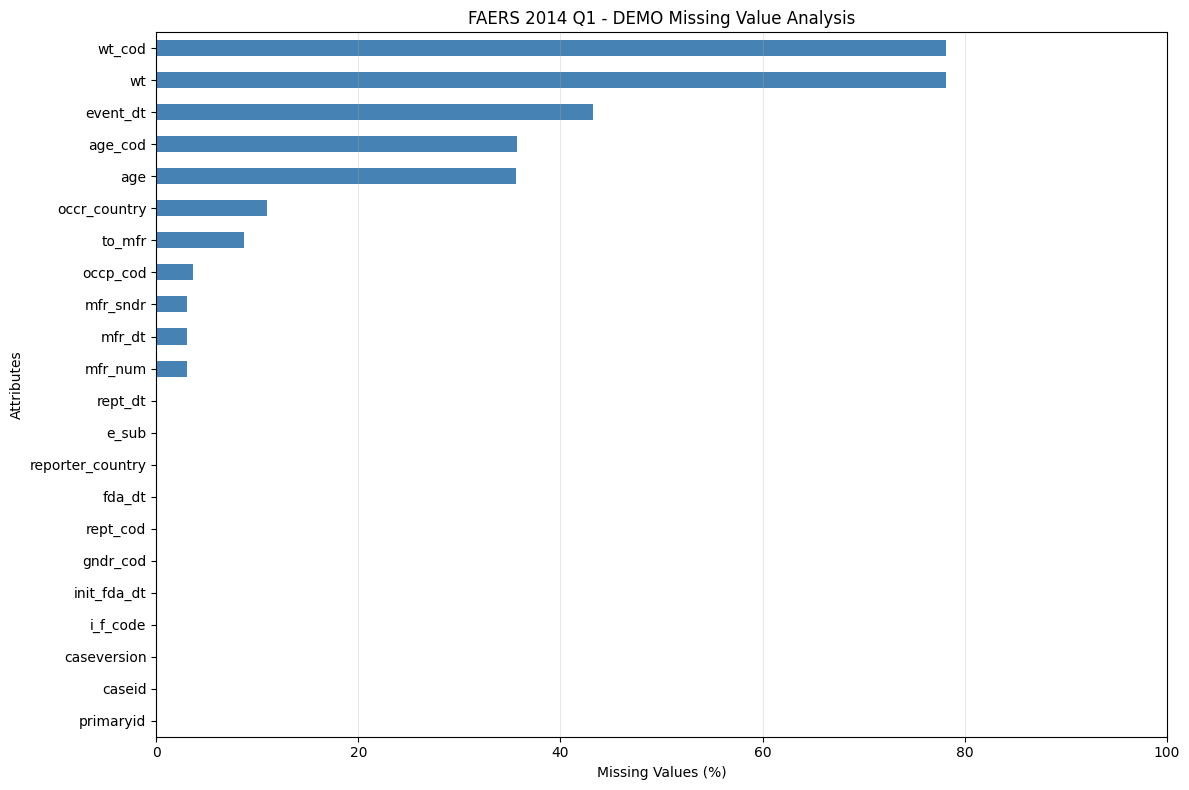

In [ ]:
plt.figure(figsize=(12, 8))

missing_summary["missing_percentage"].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("FAERS 2014 Q1 - DEMO Missing Value Analysis")
plt.xlabel("Missing Values (%)")
plt.ylabel("Attributes")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "demo_2014q1_missing_values.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Inspect demographic attribute values

In [ ]:
demographic_columns = [
    "age",
    "age_cod",
    "gndr_cod",
    "wt",
    "wt_cod",
    "reporter_country",
    "occr_country"
]

for column in demographic_columns:

    print(f"\nColumn: {column}")

    display(
        demo_df[column]
        .value_counts(dropna=False)
        .head(15)
    )


Column: age


,count
age,
NaN,92645
58,3821
57,3807
60,3781
55,3743
61,3654
53,3591
65,3560
59,3558



Column: age_cod


,count
age_cod,
YR,165140
NaN,92806
DY,883
MON,654
DEC,497
WK,57
HR,20



Column: gndr_cod


,count
gndr_cod,
F,155024
M,87332
NS,17663
UNK,38


... (4 outputs left out)


Column: reporter_country


,count
reporter_country,
US,166396
COUNTRY NOT SPECIFIED,41346
GB,7256
JP,5535
FR,5239
DE,4765
CA,4273
IT,3534
BR,2107



Column: occr_country


,count
occr_country,
US,177661
NaN,28403
GB,6727
JP,5429
FR,4995
CA,4866
DE,4654
IT,3106
BR,2473


In [ ]:
demo_clean_df = demo_df.copy()

age_conversion = {
    "YR": 1,
    "DEC": 10,
    "MON": 1 / 12,
    "WK": 7 / 365.25,
    "DY": 1 / 365.25,
    "HR": 1 / (365.25 * 24)
}

demo_clean_df["age_numeric"] = pd.to_numeric(
    demo_clean_df["age"],
    errors="coerce"
)

demo_clean_df["age_years"] = (
    demo_clean_df["age_numeric"]
    * demo_clean_df["age_cod"].map(age_conversion)
)

# Identify potentially implausible ages
invalid_age_mask = (
    (demo_clean_df["age_years"] < 0)
    | (demo_clean_df["age_years"] > 120)
)

print("Potentially invalid ages:", invalid_age_mask.sum())

display(
    demo_clean_df.loc[
        invalid_age_mask,
        ["primaryid", "age", "age_cod", "age_years"]
    ].head(20)
)

print("\nAge statistics before filtering:")

display(demo_clean_df["age_years"].describe())

Potentially invalid ages: 0


,primaryid,age,age_cod,age_years



Age statistics before filtering:


,age_years
count,167251.000000
mean,53.568396
std,19.050943
min,0.000000
25%,41.000000
50%,55.000000
75%,67.000000
max,104.000000


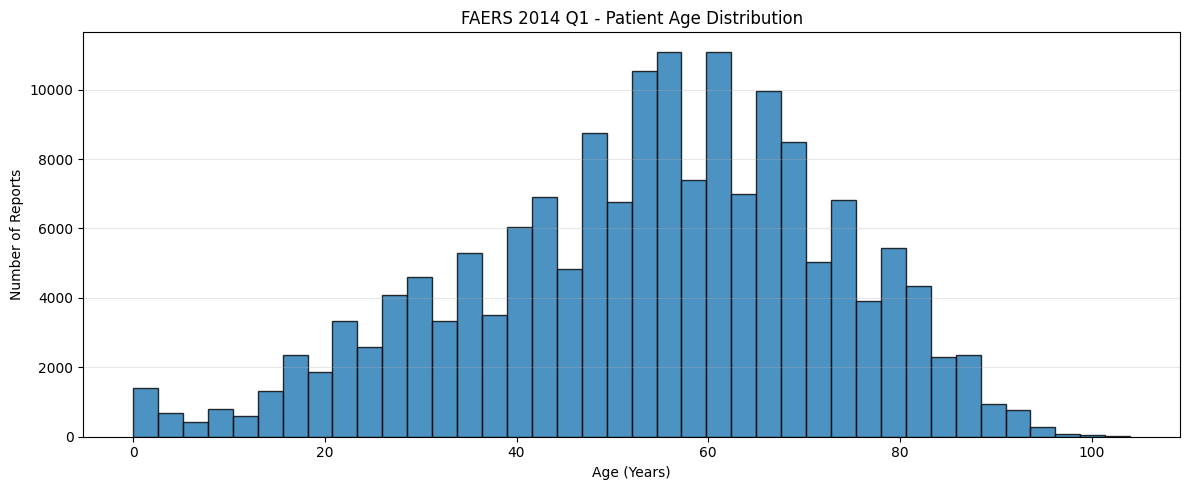

In [ ]:
valid_age_mask = demo_clean_df["age_years"].between(
    0, 120
)

plt.figure(figsize=(12, 5))

plt.hist(
    demo_clean_df.loc[valid_age_mask, "age_years"],
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.title("FAERS 2014 Q1 - Patient Age Distribution")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Reports")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "demo_age_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
gender_mapping = {
    "F": "Female",
    "M": "Male",
    "NS": "Unknown",
    "UNK": "Unknown"
}

demo_clean_df["gender_clean"] = (
    demo_clean_df["gndr_cod"]
    .map(gender_mapping)
    .fillna("Unknown")
)

demo_clean_df["gender_missing"] = (
    demo_clean_df["gender_clean"] == "Unknown"
).astype(int)

gender_summary = pd.DataFrame({
    "count": demo_clean_df["gender_clean"].value_counts(),
    "percentage": (
        demo_clean_df["gender_clean"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(gender_summary)

,count,percentage
gender_clean,,
Female,155024,59.61
Male,87332,33.58
Unknown,17701,6.81


In [ ]:
weight_conversion = {
    "KG": 1,
    "LBS": 0.45359237,
    "GMS": 0.001
}

demo_clean_df["weight_numeric"] = pd.to_numeric(
    demo_clean_df["wt"],
    errors="coerce"
)

demo_clean_df["weight_kg"] = (
    demo_clean_df["weight_numeric"]
    * demo_clean_df["wt_cod"].map(weight_conversion)
)

# Inspect unsupported weight units
invalid_weight_units = demo_clean_df[
    demo_clean_df["wt_cod"].notna()
    & ~demo_clean_df["wt_cod"].isin(weight_conversion)
]

print("Records with invalid weight units:")

display(
    invalid_weight_units[
        ["primaryid", "wt", "wt_cod"]
    ]
)

# Inspect potentially implausible weight values
invalid_weight_mask = (
    (demo_clean_df["weight_kg"] <= 0)
    | (demo_clean_df["weight_kg"] > 500)
)

print(
    "Potentially invalid weights:",
    invalid_weight_mask.sum()
)

display(
    demo_clean_df.loc[
        invalid_weight_mask,
        ["primaryid", "wt", "wt_cod", "weight_kg"]
    ].head(20)
)

print("\nWeight statistics:")

display(demo_clean_df["weight_kg"].describe())

Records with invalid weight units:


,primaryid,wt,wt_cod
43323,104042222,49,YR


Potentially invalid weights: 18


,primaryid,wt,wt_cod,weight_kg
32972,100436831,0,KG,0.0
33033,100437601,0,KG,0.0
71139,97762502,0,KG,0.0
71166,97763833,0,KG,0.0
71460,97776012,0,KG,0.0
78116,97954811,0,KG,0.0
109122,98310971,0,KG,0.0
122459,98489371,754.5,KG,754.5
122466,98489461,0,KG,0.0
130337,98584921,0,KG,0.0



Weight statistics:


,weight_kg
count,56771.000000
mean,76.069473
std,25.068899
min,0.000000
25%,61.000000
50%,74.000000
75%,89.600000
max,754.500000


In [ ]:
for column in ["reporter_country", "occr_country"]:

    demo_clean_df[f"{column}_clean"] = (
        demo_clean_df[column]
        .str.strip()
        .str.upper()
        .replace({
            "COUNTRY NOT SPECIFIED": np.nan,
            "UNKNOWN": np.nan,
            "": np.nan
        })
    )

    print(f"\n{column}:")

    print(
        "Missing percentage after cleaning:",
        round(
            demo_clean_df[f"{column}_clean"]
            .isna().mean() * 100,
            2
        )
    )


reporter_country:
Missing percentage after cleaning: 15.9

occr_country:
Missing percentage after cleaning: 10.92


Handle invalid values and create missing indicators

In [ ]:
# Apply age screening
demo_clean_df.loc[
    invalid_age_mask, "age_years"
] = np.nan

# Apply weight screening
demo_clean_df.loc[
    invalid_weight_mask, "weight_kg"
] = np.nan

# Create missing indicators
demo_clean_df["age_missing"] = (
    demo_clean_df["age_years"].isna()
).astype(int)

demo_clean_df["weight_missing"] = (
    demo_clean_df["weight_kg"].isna()
).astype(int)

# Final demographic feature availability
feature_columns = [
    "age_years",
    "gender_clean",
    "weight_kg",
    "reporter_country_clean",
    "occr_country_clean"
]

availability = demo_clean_df[feature_columns].notna()

# Explicit unknown gender is also unavailable
availability["gender_clean"] = (
    demo_clean_df["gender_clean"].isin(["Female", "Male"])
)

demographic_summary = pd.DataFrame({
    "available_count": availability.sum(),
    "missing_count": (~availability).sum(),
    "availability_percentage": (
        availability.mean() * 100
    ).round(2)
})

display(demographic_summary)

,available_count,missing_count,availability_percentage
age_years,167251,92806,64.31
gender_clean,242356,17701,93.19
weight_kg,56753,203304,21.82
reporter_country_clean,218709,41348,84.10
occr_country_clean,231654,28403,89.08


In [ ]:
demographic_features = [
    "primaryid",
    "caseid",
    "caseversion",
    "age_years",
    "age_missing",
    "gender_clean",
    "gender_missing",
    "weight_kg",
    "weight_missing",
    "reporter_country_clean",
    "occr_country_clean",
    "event_dt",
    "init_fda_dt",
    "fda_dt"
]

demo_features_df = demo_clean_df[
    demographic_features
].copy()

demo_features_df.to_csv(
    os.path.join(
        output_dir,
        "demo_2014q1_cleaned.csv"
    ),
    index=False
)

demographic_summary.to_csv(
    os.path.join(
        output_dir,
        "demo_2014q1_feature_availability.csv"
    )
)

print("Cleaned demographic dataset saved.")
print("Dataset shape:", demo_features_df.shape)

display(demo_features_df.head())

Cleaned demographic dataset saved.
Dataset shape: (260057, 14)


,primaryid,caseid,caseversion,age_years,age_missing,gender_clean,gender_missing,weight_kg,weight_missing,reporter_country_clean,occr_country_clean,event_dt,init_fda_dt,fda_dt
0,100033001,10003300,1,77.0,0,Female,0,NaN,1,US,NaN,NaN,20140306,20140306
1,100033011,10003301,1,NaN,1,Female,0,NaN,1,US,NaN,NaN,20140228,20140228
2,100033021,10003302,1,NaN,1,Male,0,NaN,1,US,US,NaN,20140312,20140312
3,100033051,10003305,1,48.0,0,Female,0,NaN,1,US,US,NaN,20140312,20140312
4,100033061,10003306,1,NaN,1,Female,0,NaN,1,US,US,NaN,20140312,20140312


Load the AEOLUS case mapping

In [ ]:
aeolus_mapping_path = (
    "/content/drive/MyDrive/aeolus_processed/"
    "clean_case_mapping.csv"
)

aeolus_case_df = pd.read_csv(
    aeolus_mapping_path,
    dtype=str
)

print("AEOLUS mapping shape:", aeolus_case_df.shape)

print("\nAvailable columns:")
print(aeolus_case_df.columns.tolist())

display(aeolus_case_df.head(10))

print("\nSample report IDs:")
print(aeolus_case_df["report_id"].head(10).tolist())

AEOLUS mapping shape: (4927437, 2)

Available columns:
['report_id', 'caseid']


,report_id,caseid
0,95686911,9568691
1,90722901,9072290
2,106851481,10685148
3,95985971,9598597
4,100587681,10058768
5,103308931,10330893
6,94553081,9455308
7,4648522,5758284
8,102558792,10255879
9,6444058,7162636



Sample report IDs:
['95686911', '90722901', '106851481', '95985971', '100587681', '103308931', '94553081', '4648522', '102558792', '6444058']


In [ ]:
aeolus_case_ids = set(
    aeolus_case_df["caseid"].dropna()
)

faers_case_ids = set(
    demo_features_df["caseid"].dropna()
)

matched_case_ids = (
    aeolus_case_ids & faers_case_ids
)

print("AEOLUS unique cases:", len(aeolus_case_ids))
print("FAERS unique cases:", len(faers_case_ids))
print("Matching case IDs:", len(matched_case_ids))

print(
    "Unmatched FAERS case IDs:",
    len(faers_case_ids - aeolus_case_ids)
)

print(
    "FAERS case matching percentage:",
    round(
        len(matched_case_ids) /
        len(faers_case_ids) * 100,
        2
    ),
    "%"
)

AEOLUS unique cases: 4927437
FAERS unique cases: 260057
Matching case IDs: 259169
Unmatched FAERS case IDs: 888
FAERS case matching percentage: 99.66 %


Check exact report-level matching

In [ ]:
# Filter AEOLUS to relevant FAERS cases
aeolus_subset = aeolus_case_df[
    aeolus_case_df["caseid"].isin(
        demo_features_df["caseid"]
    )
].copy()

print("Relevant AEOLUS records:", len(aeolus_subset))

# Rename report identifier for clarity
aeolus_subset = aeolus_subset.rename(
    columns={"report_id": "aeolus_report_id"}
)

# Match using case ID
matching_df = demo_features_df.merge(
    aeolus_subset,
    on="caseid",
    how="left",
    validate="one_to_one"
)

# Classify matching scenarios
matching_df["match_type"] = np.select(
    [
        matching_df["aeolus_report_id"].isna(),

        matching_df["primaryid"].eq(
            matching_df["aeolus_report_id"]
        )
    ],
    [
        "No Case Match",
        "Exact Report Match"
    ],
    default="Case Only Match"
)

match_summary = pd.DataFrame({
    "count": matching_df["match_type"].value_counts(),
    "percentage": (
        matching_df["match_type"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(match_summary)

Relevant AEOLUS records: 259169


,count,percentage
match_type,,
Exact Report Match,256509,98.64
Case Only Match,2660,1.02
No Case Match,888,0.34


In [ ]:
case_only_matches = matching_df[
    matching_df["match_type"] == "Case Only Match"
].copy()

print("Case-only matches:", len(case_only_matches))

display(
    case_only_matches[
        [
            "caseid",
            "primaryid",
            "aeolus_report_id",
            "caseversion",
            "fda_dt"
        ]
    ].head(20)
)

Case-only matches: 2660


,caseid,primaryid,aeolus_report_id,caseversion,fda_dt
229,10003551,100035511,100035512,1,20140312
459,10003809,100038091,100038092,1,20140312
528,10003890,100038902,100038904,2,20140314
736,10004153,100041531,100041532,1,20140312
974,10004437,100044371,100044373,1,20140312
1123,10004603,100046032,100046033,2,20140312
1492,10005041,100050411,100050412,1,20140312
1626,10005192,100051921,100051922,1,20140312
1850,10005447,100054472,100054473,2,20140312
1875,10005479,100054791,100054792,1,20140313


In [ ]:
exact_matches = matching_df[
    matching_df["match_type"] == "Exact Report Match"
].copy()

print("Exact matching reports:", len(exact_matches))

feature_columns = [
    "age_years",
    "gender_clean",
    "weight_kg",
    "reporter_country_clean",
    "occr_country_clean"
]

availability = exact_matches[feature_columns].notna()

availability["gender_clean"] = (
    exact_matches["gender_clean"]
    .isin(["Female", "Male"])
)

exact_match_availability = pd.DataFrame({
    "available_count": availability.sum(),
    "missing_count": (~availability).sum(),
    "availability_percentage": (
        availability.mean() * 100
    ).round(2)
})

display(exact_match_availability)

Exact matching reports: 256509


,available_count,missing_count,availability_percentage
age_years,165089,91420,64.36
gender_clean,239152,17357,93.23
weight_kg,55823,200686,21.76
reporter_country_clean,215259,41250,83.92
occr_country_clean,228349,28160,89.02


In [ ]:
import zipfile

aeolus_zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

case_columns = [
    "caseid",
    "primaryid",
    "isr"
]

matched_case_parts = []

with zipfile.ZipFile(aeolus_zip_path, "r") as archive:
    with archive.open("standard_unique_all_case.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=case_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=200000
        ):
            matched = chunk[
                chunk["caseid"].isin(exact_matches["caseid"])
            ]

            if not matched.empty:
                matched_case_parts.append(matched.copy())

original_case_subset = pd.concat(
    matched_case_parts,
    ignore_index=True
)

verified_matches = exact_matches.merge(
    original_case_subset[["caseid", "primaryid"]],
    on=["caseid", "primaryid"],
    how="inner",
    validate="one_to_one"
)

print("Original exact matches:", len(exact_matches))
print("Verified primary ID matches:", len(verified_matches))

print(
    "Unverified matches:",
    len(exact_matches) - len(verified_matches)
)

Original exact matches: 256509
Verified primary ID matches: 256509
Unverified matches: 0


In [ ]:
aeolus_processed_dir = (
    "/content/drive/MyDrive/aeolus_processed"
)

ps_dataset_path = os.path.join(
    aeolus_processed_dir,
    "provisional_ps_drug_report_clean.csv"
)

ps_sample = pd.read_csv(
    ps_dataset_path,
    dtype=str,
    nrows=10
)

print("Available columns:")
print(ps_sample.columns.tolist())

display(ps_sample)

Available columns:
['report_id', 'standard_concept_id', 'role_cod', 'provisional_hypersensitivity_label']


,report_id,standard_concept_id,role_cod,provisional_hypersensitivity_label
0,PRIMARY_92198372,1110942,PS,0
1,ISR_4634879,1589505,PS,0
2,PRIMARY_85958942,904453,PS,0
3,ISR_7853740,1321636,PS,0
4,ISR_5234001,1119119,PS,0
5,ISR_6614986,1589505,PS,0
6,PRIMARY_90812211,1119119,PS,0
7,ISR_4641495,1547504,PS,0
8,ISR_6494023,757688,PS,0
9,PRIMARY_89439771,1151789,PS,0


In [ ]:
verified_report_ids = set(
    verified_matches["primaryid"]
)

matched_ps_parts = []

for chunk in pd.read_csv(
    ps_dataset_path,
    dtype=str,
    chunksize=200000
):
    # Extract numeric portion of report_id by removing 'PRIMARY_' or 'ISR_'
    clean_report_id = chunk["report_id"].str.replace(r'^(PRIMARY_|ISR_)', '', regex=True)

    # Identify matches using the cleaned IDs
    matched = chunk[clean_report_id.isin(verified_report_ids)]

    if not matched.empty:
        matched_ps_parts.append(matched.copy())

matched_ps_df = pd.concat(
    matched_ps_parts,
    ignore_index=True
)

print("Matching PS drug records:", len(matched_ps_df))

print(
    "Unique matching PS reports:",
    matched_ps_df["report_id"].nunique()
)

print(
    "Unique drug concepts:",
    matched_ps_df["standard_concept_id"].nunique()
)

print(
    "Verified FAERS reports with PS records:",
    round(
        matched_ps_df["report_id"].nunique()
        / len(verified_matches) * 100,
        2
    ),
    "%"
)

display(matched_ps_df.head())

Matching PS drug records: 251245
Unique matching PS reports: 251245
Unique drug concepts: 1331
Verified FAERS reports with PS records: 97.95 %


,report_id,standard_concept_id,role_cod,provisional_hypersensitivity_label
0,PRIMARY_92198372,1110942,PS,0
1,PRIMARY_98124391,735843,PS,0
2,PRIMARY_98164081,917336,PS,0
3,PRIMARY_98972741,1397141,PS,0
4,PRIMARY_100338831,723013,PS,0


Merge AEOLUS and FAERS demographics

In [ ]:
# Create compatible report identifiers
faers_verified_df = verified_matches.copy()

faers_verified_df["report_id"] = (
    "PRIMARY_" + faers_verified_df["primaryid"]
)

# Remove redundant identifier
faers_verified_df = faers_verified_df.drop(
    columns=["aeolus_report_id", "match_type"],
    errors="ignore"
)

# Integrate demographic information
integrated_df = matched_ps_df.merge(
    faers_verified_df,
    on="report_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Integrated dataset shape:", integrated_df.shape)

print("\nMerge results:")
display(integrated_df["_merge"].value_counts())

# Verify that all records were successfully matched
assert len(integrated_df) == len(matched_ps_df)
assert integrated_df["_merge"].eq("both").all()

integrated_df = integrated_df.drop(columns="_merge")

display(integrated_df.head())

Integrated dataset shape: (251245, 19)

Merge results:


,count
_merge,
both,251245
left_only,0
right_only,0


,report_id,standard_concept_id,role_cod,provisional_hypersensitivity_label,primaryid,caseid,caseversion,age_years,age_missing,gender_clean,gender_missing,weight_kg,weight_missing,reporter_country_clean,occr_country_clean,event_dt,init_fda_dt,fda_dt
0,PRIMARY_92198372,1110942,PS,0,92198372,9219837,2,NaN,1,Female,0,60.00,0,JP,JP,20110802,20130409,20140106
1,PRIMARY_98124391,735843,PS,0,98124391,9812439,1,NaN,1,Female,0,NaN,1,US,US,NaN,20140113,20140113
2,PRIMARY_98164081,917336,PS,0,98164081,9816408,1,18.0,0,Male,0,58.97,0,US,US,20130809,20140114,20140114
3,PRIMARY_98972741,1397141,PS,0,98972741,9897274,1,NaN,1,Unknown,1,NaN,1,DK,DK,NaN,20140214,20140214
4,PRIMARY_100338831,723013,PS,0,100338831,10033883,1,50.0,0,Male,0,NaN,1,US,US,NaN,20140325,20140325


In [ ]:
label_col = "provisional_hypersensitivity_label"

integrated_df[label_col] = pd.to_numeric(
    integrated_df[label_col],
    errors="raise"
).astype(int)

assert integrated_df[label_col].isin([0, 1]).all()

label_summary = pd.DataFrame({
    "count": integrated_df[label_col].value_counts(),
    "percentage": (
        integrated_df[label_col]
        .value_counts(normalize=True) * 100
    ).round(2)
}).sort_index()

display(label_summary)

positive_count = (integrated_df[label_col] == 1).sum()
negative_count = (integrated_df[label_col] == 0).sum()

print("Positive reports:", positive_count)
print("Negative reports:", negative_count)

if positive_count > 0:
    print(
        "Negative-to-positive ratio:",
        round(negative_count / positive_count, 2)
    )

,count,percentage
provisional_hypersensitivity_label,,
0,245919,97.88
1,5326,2.12


Positive reports: 5326
Negative reports: 245919
Negative-to-positive ratio: 46.17


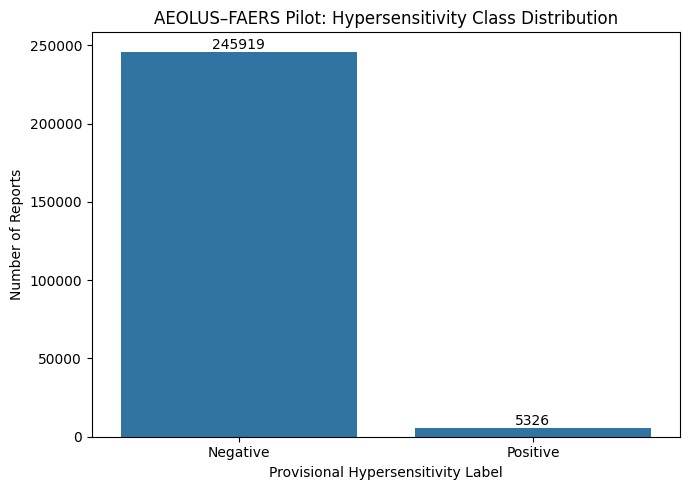

In [ ]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=integrated_df,
    x=label_col
)

ax.set_xticks([0, 1])
ax.set_xticklabels([
    "Negative",
    "Positive"
])

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.title(
    "AEOLUS–FAERS Pilot: Hypersensitivity Class Distribution"
)
plt.xlabel("Provisional Hypersensitivity Label")
plt.ylabel("Number of Reports")
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "pilot_hypersensitivity_distribution.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
feature_availability = pd.DataFrame({
    "label": integrated_df[label_col],

    "Age": integrated_df["age_years"].notna(),

    "Gender": integrated_df["gender_clean"].isin(
        ["Female", "Male"]
    ),

    "Weight": integrated_df["weight_kg"].notna(),

    "Reporter Country": (
        integrated_df["reporter_country_clean"].notna()
    ),

    "Occurrence Country": (
        integrated_df["occr_country_clean"].notna()
    )
})

availability_by_class = (
    feature_availability
    .groupby("label")
    .mean()
    .mul(100)
    .round(2)
    .T
    .reindex(columns=[0, 1])
)

availability_by_class.columns = [
    "Negative (%)",
    "Positive (%)"
]

availability_by_class["Difference (pp)"] = (
    availability_by_class["Positive (%)"]
    - availability_by_class["Negative (%)"]
).round(2)

display(availability_by_class)

,Negative (%),Positive (%),Difference (pp)
Age,64.23,66.86,2.63
Gender,93.21,93.79,0.58
Weight,21.73,19.90,-1.83
Reporter Country,83.42,92.66,9.24
Occurrence Country,89.43,87.70,-1.73


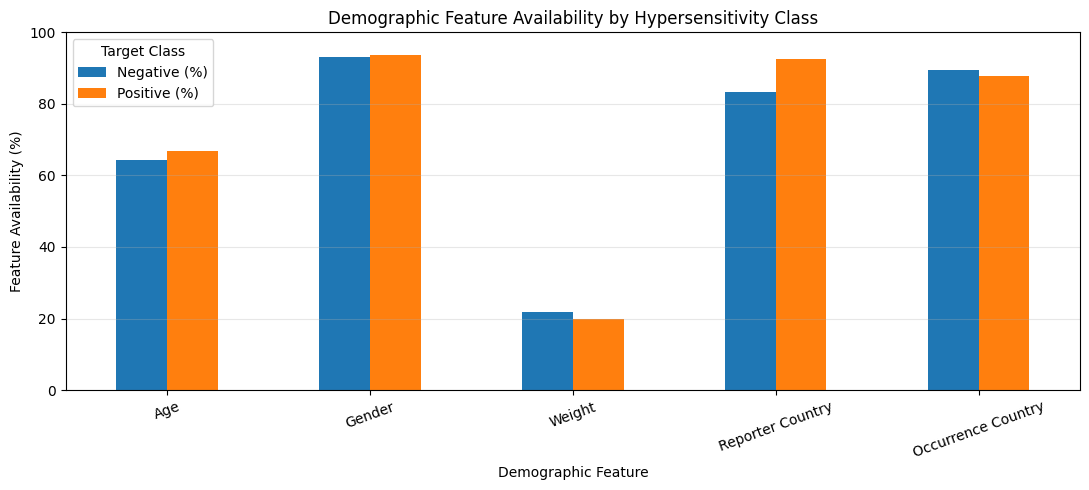

In [ ]:
availability_by_class[
    ["Negative (%)", "Positive (%)"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=20
)

plt.title(
    "Demographic Feature Availability by Hypersensitivity Class"
)

plt.ylabel("Feature Availability (%)")
plt.xlabel("Demographic Feature")
plt.ylim(0, 100)
plt.legend(title="Target Class")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "pilot_demographic_availability_by_class.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
pilot_path = os.path.join(
    output_dir,
    "aeolus_faers_2014q1_pilot.csv"
)

integrated_df.to_csv(
    pilot_path,
    index=False
)

label_summary.to_csv(
    os.path.join(
        output_dir,
        "pilot_label_summary.csv"
    )
)

availability_by_class.to_csv(
    os.path.join(
        output_dir,
        "pilot_demographic_availability_by_class.csv"
    )
)

print("Integrated pilot dataset saved.")
print("Dataset shape:", integrated_df.shape)

print(
    "File size:",
    round(os.path.getsize(pilot_path) / (1024 ** 2), 2),
    "MB"
)

print("\nAvailable columns:")
print(integrated_df.columns.tolist())

Integrated pilot dataset saved.
Dataset shape: (251245, 18)
File size: 23.02 MB

Available columns:
['report_id', 'standard_concept_id', 'role_cod', 'provisional_hypersensitivity_label', 'primaryid', 'caseid', 'caseversion', 'age_years', 'age_missing', 'gender_clean', 'gender_missing', 'weight_kg', 'weight_missing', 'reporter_country_clean', 'occr_country_clean', 'event_dt', 'init_fda_dt', 'fda_dt']


FAERS DRUG dataset

In [ ]:
drug_df = pd.read_csv(
    os.path.join(faers_dir, "DRUG14Q1.txt"),
    sep="$",
    encoding="latin-1",
    dtype=str
)

print("Dataset shape:", drug_df.shape)

display(drug_df.head())

Dataset shape: (901608, 19)


,primaryid,caseid,drug_seq,role_cod,drugname,val_vbm,route,dose_vbm,cum_dose_chr,cum_dose_unit,dechal,rechal,lot_num,exp_dt,nda_num,dose_amt,dose_unit,dose_form,dose_freq
0,100033001,10003300,1,PS,BONIVA,1,INTRAVENOUS,"3 MG, 1 IN 3 M, INTRAVENOUS (NOT OTHERWISE SPE...",NaN,NaN,D,D,H6200HO3,NaN,021858,3,MG,NaN,NaN
1,100033011,10003301,1,PS,IBUPROFEN,1,NaN,NaN,NaN,NaN,U,U,NaN,NaN,17463,NaN,NaN,NaN,NaN
2,100033021,10003302,1,PS,Lyrica,1,NaN,UNK,NaN,NaN,NaN,D,NaN,NaN,021446,NaN,NaN,NaN,NaN
3,100033051,10003305,1,PS,Lipitor,1,NaN,UNK,NaN,NaN,NaN,D,NaN,NaN,020702,NaN,NaN,FILM-COATED TABLET,NaN
4,100033051,10003305,2,SS,LISINOPRIL,1,NaN,UNK,NaN,NaN,NaN,D,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print("Total drug records:", len(drug_df))

print(
    "Unique reports:",
    drug_df["primaryid"].nunique()
)

print(
    "Unique cases:",
    drug_df["caseid"].nunique()
)

print(
    "Unique reported drug names:",
    drug_df["drugname"].nunique()
)

print(
    "Exact duplicate rows:",
    drug_df.duplicated().sum()
)

print(
    "Duplicate report-drug keys:",
    drug_df.duplicated(
        subset=["primaryid", "drug_seq"]
    ).sum()
)

print("\nDrug role distribution:")

display(
    drug_df["role_cod"]
    .value_counts(dropna=False)
)

Total drug records: 901608
Unique reports: 260057
Unique cases: 260057
Unique reported drug names: 58343
Exact duplicate rows: 0
Duplicate report-drug keys: 0

Drug role distribution:


,count
role_cod,
C,458323
PS,260057
SS,180168
I,3059
NaN,1


Missing value analysis

In [ ]:
drug_missing_summary = pd.DataFrame({
    "available_count": drug_df.notna().sum(),
    "missing_count": drug_df.isna().sum(),
    "missing_percentage": (
        drug_df.isna().mean() * 100
    ).round(2),
    "unique_values": drug_df.nunique()
})

drug_missing_summary = (
    drug_missing_summary.sort_values(
        "missing_percentage",
        ascending=False
    )
)

display(drug_missing_summary)

,available_count,missing_count,missing_percentage,unique_values
exp_dt,5192,896416,99.42,820
cum_dose_unit,12945,888663,98.56,18
cum_dose_chr,12988,888620,98.56,3045
dechal,30375,871233,96.63,4
lot_num,131351,770257,85.43,18287
dose_freq,261841,639767,70.96,74
nda_num,323703,577905,64.10,4747
dose_form,344849,556759,61.75,357
dose_vbm,354076,547532,60.73,69686
dose_amt,368805,532803,59.09,2706


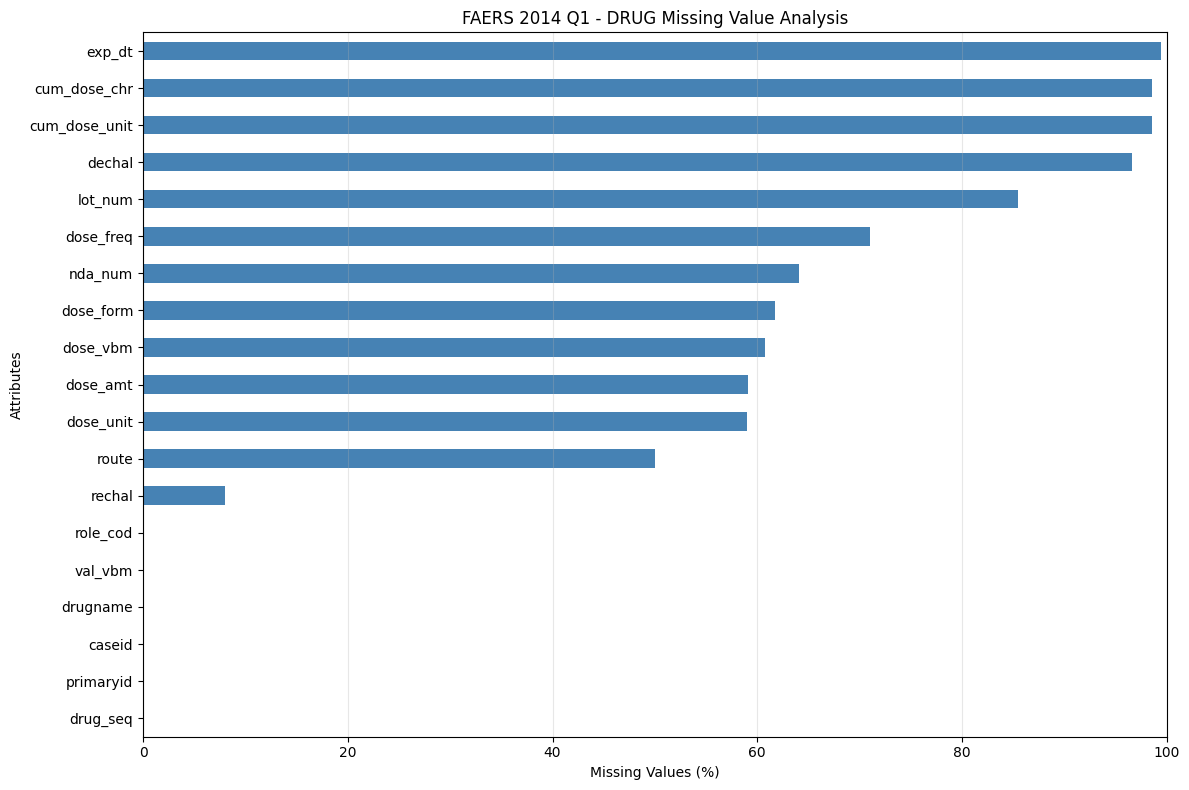

In [ ]:
plt.figure(figsize=(12, 8))

drug_missing_summary[
    "missing_percentage"
].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("FAERS 2014 Q1 - DRUG Missing Value Analysis")
plt.xlabel("Missing Values (%)")
plt.ylabel("Attributes")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "drug_2014q1_missing_values.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
faers_ps_df = drug_df[
    drug_df["role_cod"] == "PS"
].copy()

print("Primary suspect drug records:", len(faers_ps_df))

print(
    "Unique PS reports:",
    faers_ps_df["primaryid"].nunique()
)

print(
    "Unique PS drug names:",
    faers_ps_df["drugname"].nunique()
)

ps_per_report = (
    faers_ps_df.groupby("primaryid").size()
)

print(
    "Reports with multiple PS drugs:",
    (ps_per_report > 1).sum()
)

print(
    "Maximum PS drugs per report:",
    ps_per_report.max()
)

print("\nPS drugs per report distribution:")

display(
    ps_per_report.value_counts().sort_index()
)

print("\nTop 20 reported PS drug names:")

display(
    faers_ps_df["drugname"].value_counts().head(20)
)

Primary suspect drug records: 260057
Unique PS reports: 260057
Unique PS drug names: 10116
Reports with multiple PS drugs: 0
Maximum PS drugs per report: 1

PS drugs per report distribution:


,count
1,260057



Top 20 reported PS drug names:


,count
drugname,
HUMIRA,37638
Enbrel,11560
LETAIRIS,10941
TECFIDERA,5948
TYSABRI,5367
DIANEAL LOW CALCIUM,4970
Ampyra,4639
Lipitor,3750
REVLIMID,3701


In [ ]:
drug_feature_columns = [
    "route",
    "dose_amt",
    "dose_unit",
    "dose_form",
    "dose_freq"
]

for column in drug_feature_columns:

    print(f"\nColumn: {column}")

    print(
        "Missing percentage:",
        round(
            faers_ps_df[column].isna().mean() * 100,
            2
        )
    )

    display(
        faers_ps_df[column]
        .value_counts(dropna=False)
        .head(20)
    )


Column: route
Missing percentage: 25.42


,count
route,
ORAL,84620
NaN,66102
UNKNOWN,27030
SUBCUTANEOUS,26779
INTRAVENOUS,19695
INTRAMUSCULAR,7102
INTRAPERITONEAL,6509
INHALATION,3794
TRANSDERMAL,3405



Column: dose_amt
Missing percentage: 41.54


,count
dose_amt,
NaN,108019
40,26666
10,14246
50,11092
5,10048
300,6771
1,5445
20,5298
25,4887



Column: dose_unit
Missing percentage: 41.52


,count
dose_unit,
MG,124626
NaN,107979
UG,10579
DF,5762
ML,2453
GTT,1753
MG/KG,1520
MG/M**2,1497
G,1278



Column: dose_form
Missing percentage: 29.12


,count
dose_form,
NaN,75730
TABLET,36913
SOLUTION FOR INJECTION IN PRE-FILLED PEN,26547
SOLUTION FOR INJECTION IN PRE-FILLED SYRINGE,17165
CAPSULE,11563
FILM-COATED TABLET,10899
INJECTION,7879
SOLUTION FOR INJECTION,7580
SOLUTION FOR PERITONEAL DIALYSIS,6665



Column: dose_freq
Missing percentage: 55.11


,count
dose_freq,
NaN,143308
QD,38634
QOW,25788
BID,19854
/wk,14742
/month,6362
TID,2051
BIW,1603
1X,1598


Clean primary suspect drug features

In [39]:
import numpy as np

faers_ps_clean = faers_ps_df.copy()

def clean_text_column(series, unknown_values=None):

    cleaned = (
        series.astype("string")
        .str.strip()
        .str.upper()
    )

    unknown_values = set(unknown_values or [])

    unknown_values.update({
        "",
        "UNKNOWN",
        "UNK",
        "NOT SPECIFIED",
        "UNSPECIFIED"
    })

    return cleaned.mask(
        cleaned.isin(unknown_values)
    )


faers_ps_clean["drugname_clean"] = clean_text_column(
    faers_ps_clean["drugname"]
)

faers_ps_clean["route_clean"] = clean_text_column(
    faers_ps_clean["route"],
    {"NOT REPORTED"}
)

faers_ps_clean["dose_form_clean"] = clean_text_column(
    faers_ps_clean["dose_form"],
    {"UNKNOWN FORMULATION"}
)

faers_ps_clean["dose_freq_clean"] = clean_text_column(
    faers_ps_clean["dose_freq"]
)

faers_ps_clean["dose_unit_clean"] = clean_text_column(
    faers_ps_clean["dose_unit"]
)

clean_columns = [
    "drugname_clean",
    "route_clean",
    "dose_form_clean",
    "dose_freq_clean",
    "dose_unit_clean"
]

for column in clean_columns:

    print("\nColumn:", column)

    print(
        "Missing percentage:",
        round(
            faers_ps_clean[column].isna().mean() * 100,
            2
        )
    )

    print(
        "Unique values:",
        faers_ps_clean[column].nunique()
    )

    display(
        faers_ps_clean[column]
        .value_counts(dropna=False)
        .head(15)
    )


Column: drugname_clean
Missing percentage: 0.0
Unique values: 9057


,count
drugname_clean,
HUMIRA,37638
ENBREL,11611
LETAIRIS,10943
TECFIDERA,5948
TYSABRI,5367
DIANEAL LOW CALCIUM,4970
AMPYRA,4642
LIPITOR,3770
REVLIMID,3702



Column: route_clean
Missing percentage: 35.81
Unique values: 55


,count
route_clean,
<NA>,93132
ORAL,84620
SUBCUTANEOUS,26779
INTRAVENOUS,19695
INTRAMUSCULAR,7102
INTRAPERITONEAL,6509
INHALATION,3794
TRANSDERMAL,3405
INTRAUTERINE,2811



Column: dose_form_clean
Missing percentage: 31.64
Unique values: 239


,count
dose_form_clean,
<NA>,82286
TABLET,36913
SOLUTION FOR INJECTION IN PRE-FILLED PEN,26547
SOLUTION FOR INJECTION IN PRE-FILLED SYRINGE,17165
CAPSULE,11563
FILM-COATED TABLET,10899
INJECTION,7879
SOLUTION FOR INJECTION,7580
SOLUTION FOR PERITONEAL DIALYSIS,6665



Column: dose_freq_clean
Missing percentage: 55.11
Unique values: 67


,count
dose_freq_clean,
<NA>,143318
QD,38634
QOW,25788
BID,19855
/WK,14742
/MONTH,6362
TID,2051
BIW,1603
1X,1598



Column: dose_unit_clean
Missing percentage: 41.52
Unique values: 69


,count
dose_unit_clean,
MG,124631
<NA>,107979
UG,10579
DF,5762
ML,2453
GTT,1753
MG/KG,1520
MG/M**2,1497
G,1278


In [40]:
faers_ps_clean["dose_amount_numeric"] = pd.to_numeric(
    faers_ps_clean["dose_amt"],
    errors="coerce"
)

# Identify non-numeric dosage values
invalid_numeric_doses = faers_ps_clean[
    faers_ps_clean["dose_amt"].notna()
    & faers_ps_clean["dose_amount_numeric"].isna()
]

print(
    "Non-numeric dose records:",
    len(invalid_numeric_doses)
)

display(
    invalid_numeric_doses[
        ["drugname", "dose_amt", "dose_unit"]
    ].head(20)
)

# Convert only mass-based dosage units
mass_conversion = {
    "MG": 1,
    "G": 1000,
    "GM": 1000,
    "UG": 0.001,
    "MCG": 0.001
}

faers_ps_clean["dose_mg"] = (
    faers_ps_clean["dose_amount_numeric"]
    * faers_ps_clean["dose_unit_clean"].map(
        mass_conversion
    )
)

# Non-positive doses are not valid administered doses
faers_ps_clean["dose_mg"] = (
    faers_ps_clean["dose_mg"].where(
        faers_ps_clean["dose_mg"] > 0
    )
)

print("\nAvailable mass-based doses:")

print(
    faers_ps_clean["dose_mg"].notna().sum()
)

print(
    "Mass-based dose availability:",
    round(
        faers_ps_clean["dose_mg"].notna().mean() * 100,
        2
    ),
    "%"
)

print("\nDose statistics:")

display(
    faers_ps_clean["dose_mg"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

print("\nTop 20 largest converted doses:")

display(
    faers_ps_clean[
        [
            "drugname_clean",
            "dose_amt",
            "dose_unit_clean",
            "dose_mg"
        ]
    ]
    .nlargest(20, "dose_mg")
)

Non-numeric dose records: 277


,drugname,dose_amt,dose_unit
8767,"FIRMAGON /01764801/FIRMAGON) (240 MG, 80 MG) (...",240/80,MG
18917,NEUTROGENA DEEP CLEAN INVIGORATING FOAMING SCRUB,DIME SIZE,NaN
21089,CHOLECALCIFEROL,"50,000",IU
21296,TYVASO,18-54,UG
22420,LIORESAL,"1,000",UG
34311,LISINOPRIL-HCTZ,10/12.5,MG
34880,TYVASO,18-54,UG
34931,TYVASO,18-54,UG
35939,TYVASO,18-54,UG
36120,TYVASO,18-54,UG



Available mass-based doses:
136642
Mass-based dose availability: 52.54 %

Dose statistics:


,dose_mg
count,1.366420e+05
mean,2.738804e+02
std,8.461188e+03
min,6.000000e-06
1%,1.800000e-02
5%,3.000000e-02
50%,4.000000e+01
95%,6.000000e+02
99%,2.250000e+03
max,2.000000e+06



Top 20 largest converted doses:


,drugname_clean,dose_amt,dose_unit_clean,dose_mg
553869,METFORMIN (UNKNOWN),2000,G,2000000.0
392350,(GEMCITABINE HYDROCHLORIDE),1700,GM,1700000.0
447805,MESAVANCOL,1200,G,1200000.0
389060,CHLOROQUINE,548,GM,548000.0
662545,REMICADE,500,GM,500000.0
390221,CHLOROQUINE,274,GM,274000.0
773132,DEPAKOTE ER,250,G,250000.0
486122,ZELBORAF,240,G,240000.0
897870,TECFIDERA,240,G,240000.0
250646,MIRALAX,238,G,238000.0


In [41]:
drug_count_df = (
    drug_df.groupby("primaryid")["drug_seq"]
    .nunique()
    .rename("total_drug_count")
    .reset_index()
)

role_counts = pd.crosstab(
    drug_df["primaryid"],
    drug_df["role_cod"]
)

role_counts = role_counts.reindex(
    columns=["PS", "SS", "C", "I"],
    fill_value=0
)

role_counts = role_counts.rename(columns={
    "PS": "primary_suspect_count",
    "SS": "secondary_suspect_count",
    "C": "concomitant_drug_count",
    "I": "interacting_drug_count"
}).reset_index()

drug_count_df = drug_count_df.merge(
    role_counts,
    on="primaryid",
    how="left",
    validate="one_to_one"
)

print("Dataset shape:", drug_count_df.shape)

display(drug_count_df.head())

print("\nMedication count statistics:")

display(drug_count_df.describe())

print("\nReports with at least 5 recorded drug entries:")

print(
    (drug_count_df["total_drug_count"] >= 5).sum()
)

print(
    "Percentage:",
    round(
        (drug_count_df["total_drug_count"] >= 5)
        .mean() * 100,
        2
    ),
    "%"
)

print("\nMaximum drug count:")

print(drug_count_df["total_drug_count"].max())

Dataset shape: (260057, 6)


,primaryid,total_drug_count,primary_suspect_count,secondary_suspect_count,concomitant_drug_count,interacting_drug_count
0,100033001,1,1,0,0,0
1,100033011,1,1,0,0,0
2,100033021,1,1,0,0,0
3,100033051,6,1,5,0,0
4,100033061,2,1,1,0,0



Medication count statistics:


,total_drug_count,primary_suspect_count,secondary_suspect_count,concomitant_drug_count,interacting_drug_count
count,260057.000000,260057.0,260057.000000,260057.000000,260057.000000
mean,3.466963,1.0,0.692802,1.762394,0.011763
std,4.439960,0.0,1.649101,3.933839,0.242421
min,1.000000,1.0,0.000000,0.000000,0.000000
25%,1.000000,1.0,0.000000,0.000000,0.000000
50%,2.000000,1.0,0.000000,0.000000,0.000000
75%,4.000000,1.0,1.000000,2.000000,0.000000
max,204.000000,1.0,81.000000,184.000000,35.000000



Reports with at least 5 recorded drug entries:
58614
Percentage: 22.54 %

Maximum drug count:
204


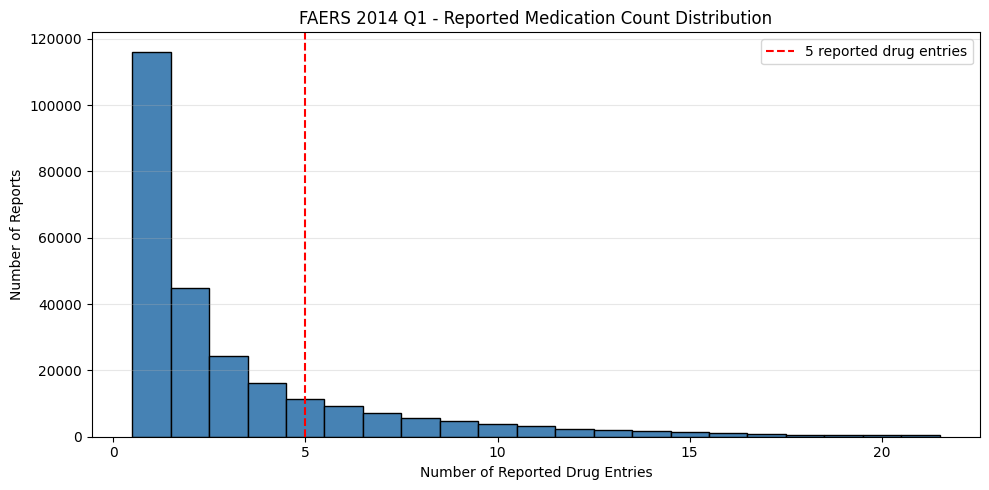

99th percentile: 21.0
Records excluded from visualisation: 2194


In [42]:
plt.figure(figsize=(10, 5))

# Limit the visualisation to the central distribution
upper_limit = drug_count_df[
    "total_drug_count"
].quantile(0.99)

plot_data = drug_count_df.loc[
    drug_count_df["total_drug_count"] <= upper_limit,
    "total_drug_count"
]

plt.hist(
    plot_data,
    bins=range(1, int(upper_limit) + 2),
    color="steelblue",
    edgecolor="black",
    align="left"
)

plt.axvline(
    5,
    color="red",
    linestyle="--",
    label="5 reported drug entries"
)

plt.title(
    "FAERS 2014 Q1 - Reported Medication Count Distribution"
)

plt.xlabel("Number of Reported Drug Entries")
plt.ylabel("Number of Reports")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        output_dir,
        "drug_count_distribution_2014q1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "99th percentile:",
    upper_limit
)

print(
    "Records excluded from visualisation:",
    len(drug_count_df) - len(plot_data)
)

In [43]:
aeolus_zip_path = "/content/drive/MyDrive/aeolus_v1.zip"

aeolus_drug_columns = [
    "primaryid",
    "isr",
    "drug_seq",
    "role_cod",
    "standard_concept_id"
]

pilot_primary_ids = set(
    integrated_df["primaryid"].astype(str)
)

matched_aeolus_parts = []

with zipfile.ZipFile(aeolus_zip_path, "r") as archive:

    with archive.open("standard_case_drug.tsv") as file:

        for chunk in pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=aeolus_drug_columns,
            dtype=str,
            na_values=["\\N"],
            chunksize=200000
        ):

            matched = chunk[
                (chunk["role_cod"] == "PS")
                & chunk["primaryid"].isin(pilot_primary_ids)
            ]

            if not matched.empty:
                matched_aeolus_parts.append(matched.copy())

aeolus_pilot_ps = pd.concat(
    matched_aeolus_parts,
    ignore_index=True
)

print("AEOLUS PS records:", len(aeolus_pilot_ps))

print(
    "Unique reports:",
    aeolus_pilot_ps["primaryid"].nunique()
)

print(
    "Duplicate report-drug-concept keys:",
    aeolus_pilot_ps.duplicated(
        subset=[
            "primaryid",
            "drug_seq",
            "standard_concept_id"
        ]
    ).sum()
)

display(aeolus_pilot_ps.head(10))

AEOLUS PS records: 251245
Unique reports: 251245
Duplicate report-drug-concept keys: 0


,primaryid,isr,drug_seq,role_cod,standard_concept_id
0,92198372,NaN,1,PS,1110942
1,98124391,NaN,1,PS,735843
2,98164081,NaN,1,PS,917336
3,98972741,NaN,1,PS,1397141
4,100338831,NaN,1,PS,723013
5,99801681,NaN,1,PS,1119119
6,99110562,NaN,1,PS,1337068
7,63758494,NaN,1,PS,1319193
8,100176941,NaN,1,PS,1315411
9,99185481,NaN,1,PS,43526424


In [44]:
aeolus_pilot_keys = integrated_df[
    [
        "primaryid",
        "standard_concept_id"
    ]
].merge(
    aeolus_pilot_ps[
        [
            "primaryid",
            "standard_concept_id",
            "drug_seq"
        ]
    ].drop_duplicates(),
    on=[
        "primaryid",
        "standard_concept_id"
    ],
    how="left",
    indicator=True
)

print("AEOLUS concept matching results:")

display(
    aeolus_pilot_keys["_merge"].value_counts()
)

print(
    "Reports with multiple matching sequences:",
    aeolus_pilot_keys["primaryid"].duplicated().sum()
)

aeolus_pilot_keys = aeolus_pilot_keys.drop(
    columns="_merge"
)

aeolus_pilot_keys = aeolus_pilot_keys.rename(
    columns={"drug_seq": "aeolus_drug_seq"}
)

faers_ps_keys = faers_ps_clean[
    [
        "primaryid",
        "drug_seq",
        "drugname_clean"
    ]
].rename(
    columns={"drug_seq": "faers_drug_seq"}
)

drug_matching_df = aeolus_pilot_keys.merge(
    faers_ps_keys,
    on="primaryid",
    how="left",
    validate="many_to_one",
    indicator=True
)

drug_matching_df["sequence_match"] = (
    drug_matching_df["aeolus_drug_seq"].notna()
    & drug_matching_df["faers_drug_seq"].notna()
    & drug_matching_df["aeolus_drug_seq"].eq(
        drug_matching_df["faers_drug_seq"]
    ).fillna(False)
)

print("\nFAERS report matching results:")

display(
    drug_matching_df["_merge"].value_counts()
)

print("\nDrug sequence matching results:")

display(
    drug_matching_df["sequence_match"].value_counts()
)

print(
    "Sequence matching percentage:",
    round(
        drug_matching_df["sequence_match"].mean() * 100,
        2
    ),
    "%"
)

display(drug_matching_df.head(10))

AEOLUS concept matching results:


,count
_merge,
both,251245
left_only,0
right_only,0


Reports with multiple matching sequences: 0

FAERS report matching results:


,count
_merge,
both,251245
left_only,0
right_only,0



Drug sequence matching results:


,count
sequence_match,
True,251245


Sequence matching percentage: 100.0 %


,primaryid,standard_concept_id,aeolus_drug_seq,faers_drug_seq,drugname_clean,_merge,sequence_match
0,92198372,1110942,1,1,OMALIZUMAB,both,True
1,98124391,735843,1,1,TYSABRI,both,True
2,98164081,917336,1,1,DESOXIMETASONE CREAM USP 0.05%,both,True
3,98972741,1397141,1,1,BEVACIZUMAB,both,True
4,100338831,723013,1,1,DIAZEPAM,both,True
5,99801681,1119119,1,1,HUMIRA,both,True
6,99110562,1337068,1,1,LETAIRIS,both,True
7,63758494,1319193,1,1,IRESSA,both,True
8,100176941,1315411,1,1,ERBITUX,both,True
9,99185481,43526424,1,1,TECFIDERA,both,True


In [45]:
sequence_mismatches = drug_matching_df[
    ~drug_matching_df["sequence_match"]
].copy()

print(
    "Records with sequence mismatches:",
    len(sequence_mismatches)
)

display(
    sequence_mismatches[
        [
            "primaryid",
            "standard_concept_id",
            "aeolus_drug_seq",
            "faers_drug_seq",
            "drugname_clean"
        ]
    ].head(30)
)

Records with sequence mismatches: 0


,primaryid,standard_concept_id,aeolus_drug_seq,faers_drug_seq,drugname_clean


In [46]:
drug_feature_columns = [
    "primaryid",
    "drug_seq",
    "drugname_clean",
    "route_clean",
    "dose_form_clean",
    "dose_freq_clean",
    "dose_unit_clean",
    "dose_mg"
]

faers_drug_features = faers_ps_clean[
    drug_feature_columns
].copy()

print("Drug feature dataset shape:",
      faers_drug_features.shape)

print(
    "Duplicate report-drug keys:",
    faers_drug_features.duplicated(
        subset=["primaryid", "drug_seq"]
    ).sum()
)

display(faers_drug_features.head())

Drug feature dataset shape: (260057, 8)
Duplicate report-drug keys: 0


,primaryid,drug_seq,drugname_clean,route_clean,dose_form_clean,dose_freq_clean,dose_unit_clean,dose_mg
0,100033001,1,BONIVA,INTRAVENOUS,<NA>,<NA>,MG,3.0
1,100033011,1,IBUPROFEN,<NA>,<NA>,<NA>,<NA>,NaN
2,100033021,1,LYRICA,<NA>,<NA>,<NA>,<NA>,NaN
3,100033051,1,LIPITOR,<NA>,FILM-COATED TABLET,<NA>,<NA>,NaN
9,100033061,1,LETAIRIS,ORAL,TABLET,<NA>,MG,10.0


In [47]:
verified_drug_keys = drug_matching_df.loc[
    drug_matching_df["sequence_match"],
    ["primaryid", "standard_concept_id", "faers_drug_seq"]
].rename(
    columns={"faers_drug_seq": "drug_seq"}
)

pilot_drug_df = integrated_df.merge(
    verified_drug_keys,
    on=["primaryid", "standard_concept_id"],
    how="left",
    validate="one_to_one"
)

pilot_drug_df = pilot_drug_df.merge(
    faers_drug_features,
    on=["primaryid", "drug_seq"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Integrated dataset shape:", pilot_drug_df.shape)

print("\nMerge results:")
display(pilot_drug_df["_merge"].value_counts())

assert len(pilot_drug_df) == len(integrated_df)
assert pilot_drug_df["_merge"].eq("both").all()

pilot_drug_df = pilot_drug_df.drop(columns="_merge")

display(pilot_drug_df.head())

Integrated dataset shape: (251245, 26)

Merge results:


,count
_merge,
both,251245
left_only,0
right_only,0


,report_id,standard_concept_id,role_cod,provisional_hypersensitivity_label,primaryid,caseid,caseversion,age_years,age_missing,gender_clean,...,event_dt,init_fda_dt,fda_dt,drug_seq,drugname_clean,route_clean,dose_form_clean,dose_freq_clean,dose_unit_clean,dose_mg
0,PRIMARY_92198372,1110942,PS,0,92198372,9219837,2,NaN,1,Female,...,20110802,20130409,20140106,1,OMALIZUMAB,SUBCUTANEOUS,SOLUTION FOR INJECTION,<NA>,MG,150.0
1,PRIMARY_98124391,735843,PS,0,98124391,9812439,1,NaN,1,Female,...,NaN,20140113,20140113,1,TYSABRI,INTRAVENOUS,INTRAVENOUS INFUSION,/MONTH,MG,300.0
2,PRIMARY_98164081,917336,PS,0,98164081,9816408,1,18.0,0,Male,...,20130809,20140114,20140114,1,DESOXIMETASONE CREAM USP 0.05%,TOPICAL,<NA>,<NA>,<NA>,NaN
3,PRIMARY_98972741,1397141,PS,0,98972741,9897274,1,NaN,1,Unknown,...,NaN,20140214,20140214,1,BEVACIZUMAB,<NA>,<NA>,QOW,MG/KG,NaN
4,PRIMARY_100338831,723013,PS,0,100338831,10033883,1,50.0,0,Male,...,NaN,20140325,20140325,1,DIAZEPAM,ORAL,<NA>,<NA>,<NA>,NaN


In [49]:
pilot_drug_df = pilot_drug_df.merge(
    drug_count_df,
    on="primaryid",
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Dataset shape:", pilot_drug_df.shape)

print("\nMerge results:")
display(pilot_drug_df["_merge"].value_counts())

assert len(pilot_drug_df) == len(integrated_df)
assert pilot_drug_df["_merge"].eq("both").all()

pilot_drug_df = pilot_drug_df.drop(columns="_merge")

print("\nMedication count statistics:")

display(
    pilot_drug_df[
        [
            "total_drug_count",
            "primary_suspect_count",
            "secondary_suspect_count",
            "concomitant_drug_count",
            "interacting_drug_count"
        ]
    ].describe()
)

Dataset shape: (251245, 31)

Merge results:


,count
_merge,
both,251245
left_only,0
right_only,0



Medication count statistics:


,total_drug_count,primary_suspect_count,secondary_suspect_count,concomitant_drug_count,interacting_drug_count
count,251245.000000,251245.0,251245.000000,251245.000000,251245.000000
mean,3.475225,1.0,0.687456,1.776270,0.011495
std,4.450968,0.0,1.645474,3.948308,0.242730
min,1.000000,1.0,0.000000,0.000000,0.000000
25%,1.000000,1.0,0.000000,0.000000,0.000000
50%,2.000000,1.0,0.000000,0.000000,0.000000
75%,4.000000,1.0,1.000000,2.000000,0.000000
max,204.000000,1.0,81.000000,184.000000,35.000000


In [50]:
pilot_drug_df["route_missing"] = (
    pilot_drug_df["route_clean"].isna().astype(int)
)

pilot_drug_df["dose_form_missing"] = (
    pilot_drug_df["dose_form_clean"].isna().astype(int)
)

pilot_drug_df["dose_missing"] = (
    pilot_drug_df["dose_mg"].isna().astype(int)
)

pilot_drug_df["dose_freq_missing"] = (
    pilot_drug_df["dose_freq_clean"].isna().astype(int)
)

pilot_drug_df["high_medication_burden"] = (
    pilot_drug_df["total_drug_count"] >= 5
).astype(int)

print("Updated dataset shape:", pilot_drug_df.shape)

display(
    pilot_drug_df[
        [
            "route_missing",
            "dose_form_missing",
            "dose_missing",
            "dose_freq_missing",
            "high_medication_burden"
        ]
    ].mean().mul(100).round(2)
)

Updated dataset shape: (251245, 35)


,0
route_missing,36.07
dose_form_missing,31.31
dose_missing,46.58
dose_freq_missing,54.64
high_medication_burden,22.64


In [51]:
drug_features = [
    "drugname_clean",
    "route_clean",
    "dose_form_clean",
    "dose_freq_clean",
    "dose_unit_clean",
    "dose_mg",
    "total_drug_count",
    "concomitant_drug_count"
]

drug_availability = pd.DataFrame({
    "available_count":
        pilot_drug_df[drug_features].notna().sum(),

    "missing_count":
        pilot_drug_df[drug_features].isna().sum(),

    "availability_percentage":
        pilot_drug_df[drug_features]
        .notna().mean().mul(100).round(2),

    "unique_values":
        pilot_drug_df[drug_features].nunique()
})

display(drug_availability)

,available_count,missing_count,availability_percentage,unique_values
drugname_clean,251245,0,100.00,7184
route_clean,160611,90634,63.93,54
dose_form_clean,172579,78666,68.69,227
dose_freq_clean,113971,137274,45.36,67
dose_unit_clean,148583,102662,59.14,65
dose_mg,134220,117025,53.42,1388
total_drug_count,251245,0,100.00,95
concomitant_drug_count,251245,0,100.00,89


In [52]:
target = "provisional_hypersensitivity_label"

availability_by_class = (
    pilot_drug_df.groupby(target)[drug_features]
    .agg(lambda x: x.notna().mean() * 100)
    .T
)

availability_by_class.columns = [
    "Negative (%)",
    "Positive (%)"
]

availability_by_class["Difference (pp)"] = (
    availability_by_class["Positive (%)"]
    - availability_by_class["Negative (%)"]
)

display(availability_by_class.round(2))

,Negative (%),Positive (%),Difference (pp)
drugname_clean,100.00,100.00,0.00
route_clean,64.32,45.55,-18.77
dose_form_clean,69.01,54.02,-14.99
dose_freq_clean,45.74,27.90,-17.84
dose_unit_clean,59.55,39.94,-19.62
dose_mg,53.85,33.57,-20.28
total_drug_count,100.00,100.00,0.00
concomitant_drug_count,100.00,100.00,0.00


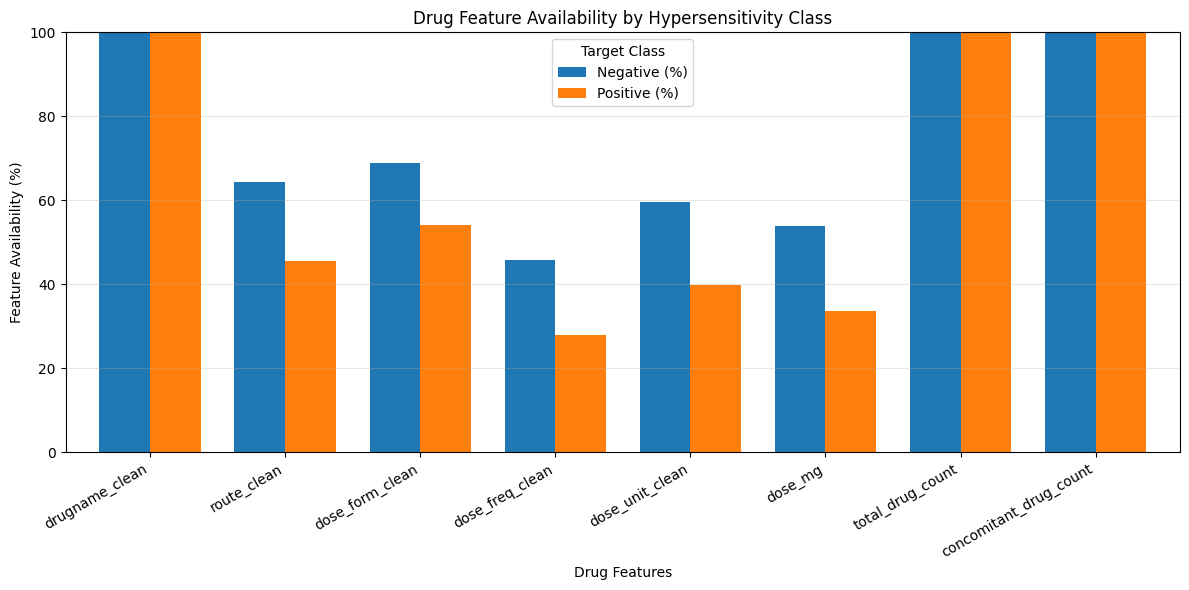

In [53]:
availability_by_class[
    ["Negative (%)", "Positive (%)"]
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title(
    "Drug Feature Availability by Hypersensitivity Class"
)

plt.ylabel("Feature Availability (%)")
plt.xlabel("Drug Features")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Target Class")
plt.tight_layout()
plt.show()

In [54]:
import os

target = "provisional_hypersensitivity_label"

assert len(pilot_drug_df) == 251245
assert pilot_drug_df["primaryid"].is_unique
assert pilot_drug_df["caseid"].is_unique
assert pilot_drug_df[target].notna().all()

assert pilot_drug_df[target].astype(int).value_counts().to_dict() == {
    0: 245919,
    1: 5326
}

output_dir = "/content/drive/MyDrive/Capstone/faers_processed"

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "aeolus_faers_2014q1_drug_integrated.csv"
)

pilot_drug_df.to_csv(output_path, index=False)

print("Integrated drug dataset saved.")
print("Dataset shape:", pilot_drug_df.shape)

print(
    "File size:",
    round(os.path.getsize(output_path) / (1024 ** 2), 2),
    "MB"
)

print("\nTarget distribution:")
display(pilot_drug_df[target].value_counts())

print("\nAvailable columns:")
print(pilot_drug_df.columns.tolist())

Integrated drug dataset saved.
Dataset shape: (251245, 35)
File size: 38.18 MB

Target distribution:


,count
provisional_hypersensitivity_label,
0,245919
1,5326



Available columns:
['report_id', 'standard_concept_id', 'role_cod', 'provisional_hypersensitivity_label', 'primaryid', 'caseid', 'caseversion', 'age_years', 'age_missing', 'gender_clean', 'gender_missing', 'weight_kg', 'weight_missing', 'reporter_country_clean', 'occr_country_clean', 'event_dt', 'init_fda_dt', 'fda_dt', 'drug_seq', 'drugname_clean', 'route_clean', 'dose_form_clean', 'dose_freq_clean', 'dose_unit_clean', 'dose_mg', 'total_drug_count', 'primary_suspect_count', 'secondary_suspect_count', 'concomitant_drug_count', 'interacting_drug_count', 'route_missing', 'dose_form_missing', 'dose_missing', 'dose_freq_missing', 'high_medication_burden']


FAERS REAC table analysis

In [55]:
faers_path = "/content/drive/MyDrive/Capstone/ascii"

reac_df = pd.read_csv(
    os.path.join(faers_path, "REAC14Q1.txt"),
    sep="$",
    dtype=str,
    encoding="latin-1",
    low_memory=False
)

reac_df.columns = (
    reac_df.columns.str.strip().str.lower()
)

print("Dataset shape:", reac_df.shape)

print("\nAvailable columns:")
print(reac_df.columns.tolist())

display(reac_df.head(10))

Dataset shape: (754668, 3)

Available columns:
['primaryid', 'caseid', 'pt']


,primaryid,caseid,pt
0,100033001,10003300,Arthralgia
1,100033001,10003300,Diarrhoea
2,100033001,10003300,Headache
3,100033001,10003300,Vomiting
4,100033011,10003301,Dyspepsia
5,100033011,10003301,Renal impairment
6,100033021,10003302,Drug ineffective
7,100033051,10003305,Drug hypersensitivity
8,100033061,10003306,Cough
9,100033061,10003306,Throat irritation


In [56]:
print("Total reaction records:", len(reac_df))

print(
    "Unique reports:",
    reac_df["primaryid"].nunique()
)

print(
    "Unique cases:",
    reac_df["caseid"].nunique()
)

print(
    "Unique reaction terms:",
    reac_df["pt"].nunique()
)

print(
    "Exact duplicate rows:",
    reac_df.duplicated().sum()
)

print(
    "Duplicate report-reaction keys:",
    reac_df.duplicated(
        subset=["primaryid", "pt"]
    ).sum()
)

reaction_quality = pd.DataFrame({
    "available_count": reac_df.notna().sum(),
    "missing_count": reac_df.isna().sum(),
    "missing_percentage": (
        reac_df.isna().mean() * 100
    ).round(2),
    "unique_values": reac_df.nunique()
})

display(reaction_quality)

Total reaction records: 754668
Unique reports: 260057
Unique cases: 260057
Unique reaction terms: 9579
Exact duplicate rows: 0
Duplicate report-reaction keys: 0


,available_count,missing_count,missing_percentage,unique_values
primaryid,754668,0,0.0,260057
caseid,754668,0,0.0,260057
pt,754668,0,0.0,9579


In [57]:
reac_df["pt_normalized"] = (
    reac_df["pt"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
)

print(
    "Unique reaction terms before normalization:",
    reac_df["pt"].nunique()
)

print(
    "Unique reaction terms after normalization:",
    reac_df["pt_normalized"].nunique()
)

print("\nTop 20 reported reaction terms:")

display(
    reac_df["pt_normalized"].value_counts().head(20)
)

Unique reaction terms before normalization: 9579
Unique reaction terms after normalization: 9579

Top 20 reported reaction terms:


,count
pt_normalized,
DRUG INEFFECTIVE,16765
DEATH,10360
FATIGUE,9409
PAIN,8968
NAUSEA,8898
HEADACHE,8647
INJECTION SITE PAIN,8555
DYSPNOEA,8103
DIARRHOEA,7309


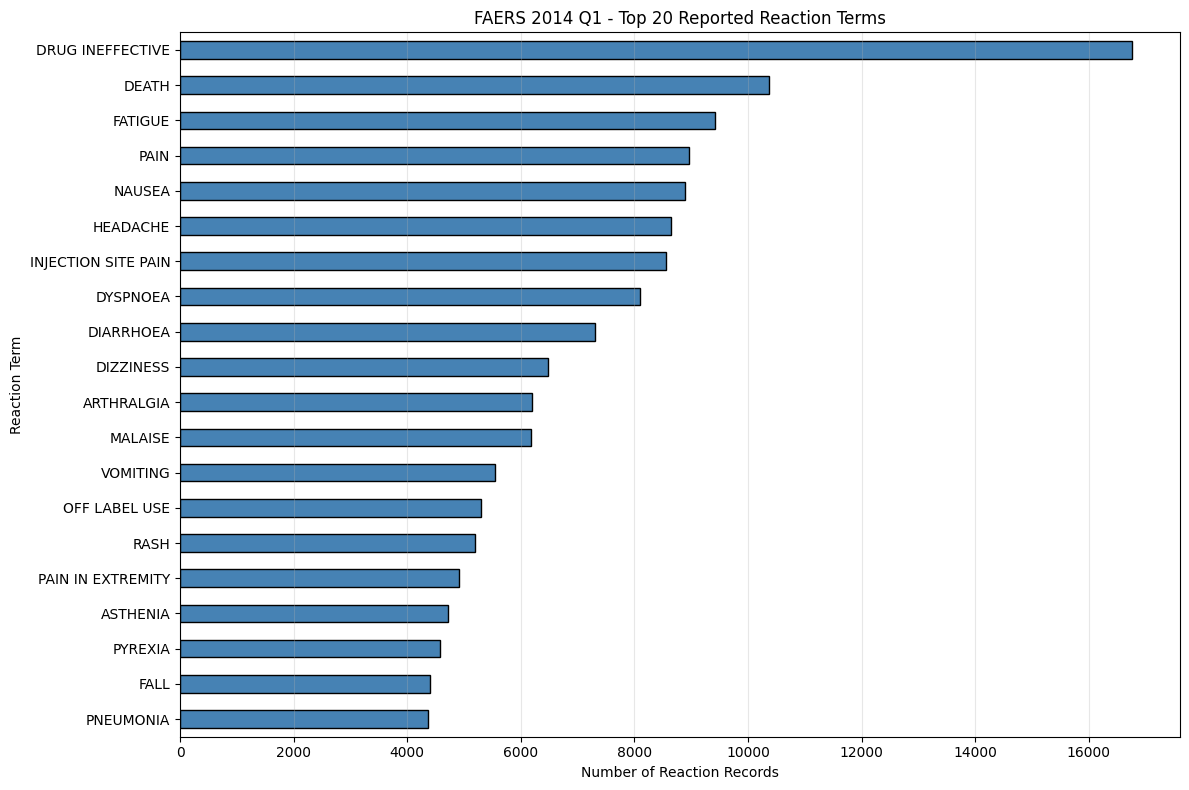

In [58]:
import matplotlib.pyplot as plt

top_reactions = (
    reac_df["pt_normalized"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(12, 8))

top_reactions.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title("FAERS 2014 Q1 - Top 20 Reported Reaction Terms")
plt.xlabel("Number of Reaction Records")
plt.ylabel("Reaction Term")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Reaction count statistics:


,pt_normalized
count,260057.000000
mean,2.901933
std,4.371917
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,200.000000


Reports with multiple reaction terms: 151893
Maximum unique reactions per report: 200
99th percentile: 16.0


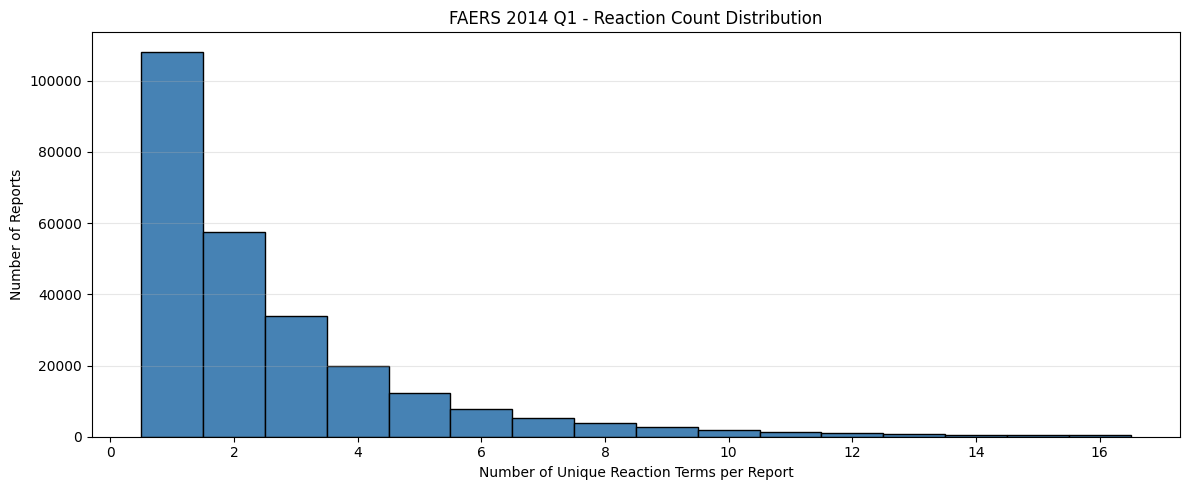

In [59]:
reaction_counts = (
    reac_df.groupby("primaryid")["pt_normalized"]
    .nunique()
)

print("Reaction count statistics:")

display(reaction_counts.describe())

print(
    "Reports with multiple reaction terms:",
    (reaction_counts > 1).sum()
)

print(
    "Maximum unique reactions per report:",
    reaction_counts.max()
)

print(
    "99th percentile:",
    reaction_counts.quantile(0.99)
)

upper_limit = reaction_counts.quantile(0.99)

plt.figure(figsize=(12, 5))

plt.hist(
    reaction_counts[reaction_counts <= upper_limit],
    bins=range(1, int(upper_limit) + 2),
    color="steelblue",
    edgecolor="black",
    align="left"
)

plt.title("FAERS 2014 Q1 - Reaction Count Distribution")
plt.xlabel("Number of Unique Reaction Terms per Report")
plt.ylabel("Number of Reports")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
core_hypersensitivity_terms = {
    "ANAPHYLACTIC REACTION",
    "ANAPHYLACTIC SHOCK",
    "ANAPHYLACTOID REACTION",
    "ANAPHYLACTOID SHOCK",
    "DOCUMENTED HYPERSENSITIVITY TO ADMINISTERED DRUG",
    "DRUG HYPERSENSITIVITY",
    "HYPERSENSITIVITY",
    "TYPE I HYPERSENSITIVITY",
    "TYPE II HYPERSENSITIVITY",
    "TYPE IV HYPERSENSITIVITY REACTION"
}

print(
    "Number of provisional hypersensitivity terms:",
    len(core_hypersensitivity_terms)
)

faers_hypersensitivity_reactions = reac_df[
    reac_df["pt_normalized"].isin(
        core_hypersensitivity_terms
    )
].copy()

print(
    "Matching reaction records:",
    len(faers_hypersensitivity_reactions)
)

print(
    "Unique hypersensitivity reports:",
    faers_hypersensitivity_reactions["primaryid"].nunique()
)

print("\nHypersensitivity term distribution:")

term_counts = (
    faers_hypersensitivity_reactions["pt_normalized"]
    .value_counts()
    .reindex(
        sorted(core_hypersensitivity_terms),
        fill_value=0
    )
    .sort_values(ascending=False)
)

display(term_counts)

Number of provisional hypersensitivity terms: 10
Matching reaction records: 5604
Unique hypersensitivity reports: 5524

Hypersensitivity term distribution:


,count
pt_normalized,
DRUG HYPERSENSITIVITY,2458
HYPERSENSITIVITY,2342
ANAPHYLACTIC REACTION,535
ANAPHYLACTIC SHOCK,183
ANAPHYLACTOID REACTION,26
TYPE I HYPERSENSITIVITY,22
TYPE IV HYPERSENSITIVITY REACTION,21
DOCUMENTED HYPERSENSITIVITY TO ADMINISTERED DRUG,9
ANAPHYLACTOID SHOCK,8


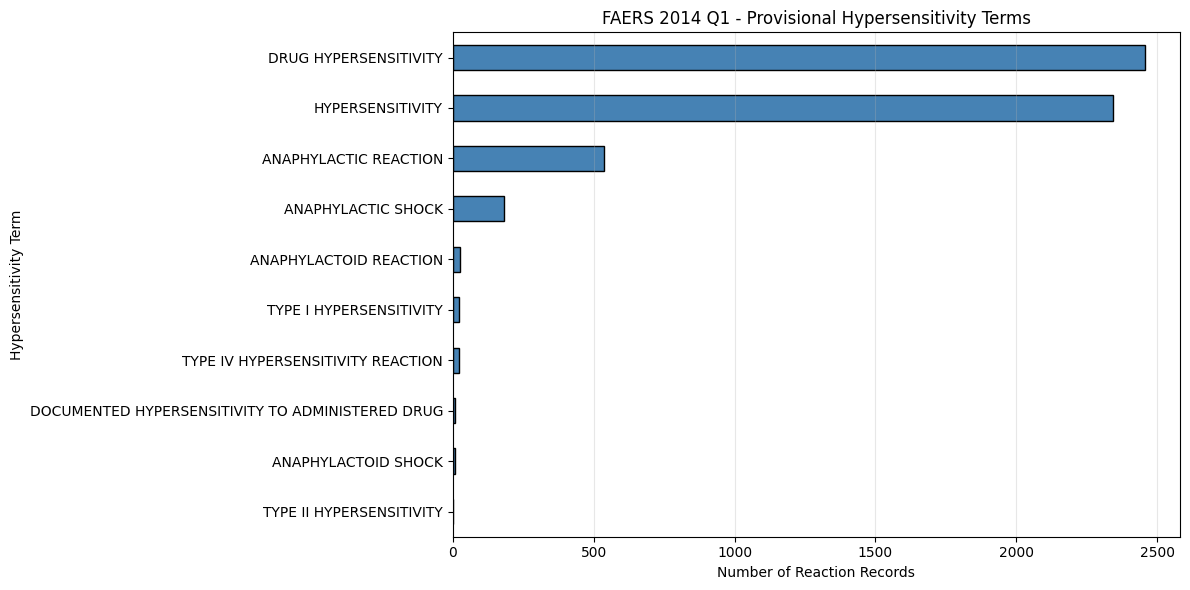

In [61]:
plt.figure(figsize=(12, 6))

term_counts.sort_values().plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title(
    "FAERS 2014 Q1 - Provisional Hypersensitivity Terms"
)

plt.xlabel("Number of Reaction Records")
plt.ylabel("Hypersensitivity Term")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
faers_report_labels = reac_df[
    ["primaryid", "caseid"]
].drop_duplicates().copy()

positive_report_ids = set(
    faers_hypersensitivity_reactions["primaryid"]
)

faers_report_labels["faers_hypersensitivity_label"] = (
    faers_report_labels["primaryid"]
    .isin(positive_report_ids)
    .astype(int)
)

assert faers_report_labels["primaryid"].is_unique

print("Dataset shape:", faers_report_labels.shape)

label_distribution = (
    faers_report_labels["faers_hypersensitivity_label"]
    .value_counts()
    .sort_index()
    .to_frame("count")
)

label_distribution["percentage"] = (
    label_distribution["count"]
    / len(faers_report_labels) * 100
).round(2)

display(label_distribution)

display(faers_report_labels.head())

Dataset shape: (260057, 3)


,count,percentage
faers_hypersensitivity_label,,
0,254533,97.88
1,5524,2.12


,primaryid,caseid,faers_hypersensitivity_label
0,100033001,10003300,0
4,100033011,10003301,0
6,100033021,10003302,0
7,100033051,10003305,1
8,100033061,10003306,0


In [63]:
label_comparison_df = pilot_drug_df[
    [
        "primaryid",
        "caseid",
        "standard_concept_id",
        "provisional_hypersensitivity_label"
    ]
].copy()

label_comparison_df = label_comparison_df.merge(
    faers_report_labels,
    on=["primaryid", "caseid"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Comparison dataset shape:",
      label_comparison_df.shape)

print("\nMerge results:")

display(
    label_comparison_df["_merge"].value_counts()
)

assert len(label_comparison_df) == len(pilot_drug_df)
assert label_comparison_df["_merge"].eq("both").all()

label_comparison_df = label_comparison_df.drop(
    columns="_merge"
)

label_comparison_df["label_agreement"] = (
    label_comparison_df["provisional_hypersensitivity_label"]
    .astype(int)
    .eq(
        label_comparison_df["faers_hypersensitivity_label"]
    )
)

print("\nLabel agreement:")

display(
    label_comparison_df["label_agreement"].value_counts()
)

print(
    "Agreement percentage:",
    round(
        label_comparison_df["label_agreement"].mean() * 100,
        4
    ),
    "%"
)

Comparison dataset shape: (251245, 6)

Merge results:


,count
_merge,
both,251245
left_only,0
right_only,0



Label agreement:


,count
label_agreement,
True,251245


Agreement percentage: 100.0 %


In [64]:
agreement_matrix = pd.crosstab(
    label_comparison_df[
        "provisional_hypersensitivity_label"
    ].astype(int),

    label_comparison_df[
        "faers_hypersensitivity_label"
    ],

    rownames=["AEOLUS Label"],
    colnames=["FAERS Label"]
).reindex(
    index=[0, 1],
    columns=[0, 1],
    fill_value=0
)

display(agreement_matrix)

FAERS Label,0,1
AEOLUS Label,,
0,245919,0
1,0,5326


In [65]:
label_disagreements = label_comparison_df[
    ~label_comparison_df["label_agreement"]
].copy()

print(
    "Total label disagreements:",
    len(label_disagreements)
)

display(label_disagreements.head(20))

disagreement_reactions = reac_df[
    reac_df["primaryid"].isin(
        label_disagreements["primaryid"]
    )
].copy()

print(
    "Reaction records associated with disagreements:",
    len(disagreement_reactions)
)

display(
    disagreement_reactions.head(30)
)

Total label disagreements: 0


,primaryid,caseid,standard_concept_id,provisional_hypersensitivity_label,faers_hypersensitivity_label,label_agreement


Reaction records associated with disagreements: 0


,primaryid,caseid,pt,pt_normalized


Understanding the THER dataset                                                               
## FAERS Therapy Data Preprocessing

The THER dataset contains drug therapy start dates,
end dates, and reported treatment duration.

This stage investigates therapy information availability,
date consistency, treatment duration standardization,
and report-drug-level integration.

Temporal features are assessed for potential target
leakage before inclusion in predictive models.

In [66]:
ther_path = (
    "/content/drive/MyDrive/Capstone/ascii/THER14Q1.txt"
)

ther_df = pd.read_csv(
    ther_path,
    sep="$",
    dtype=str,
    encoding="latin-1",
    low_memory=False
)

print("Dataset shape:", ther_df.shape)
print("Available columns:", ther_df.columns.tolist())

display(ther_df.head(10))

Dataset shape: (329817, 7)
Available columns: ['primaryid', 'caseid', 'dsg_drug_seq', 'start_dt', 'end_dt', 'dur', 'dur_cod']


,primaryid,caseid,dsg_drug_seq,start_dt,end_dt,dur,dur_cod
0,100033001,10003300,1,20130913,NaN,NaN,NaN
1,100033061,10003306,1,20111014,NaN,NaN,NaN
2,100033072,10003307,1,20110510,NaN,NaN,NaN
3,100033082,10003308,1,20101122,NaN,NaN,NaN
4,100033092,10003309,1,20120427,NaN,NaN,NaN
5,100033102,10003310,1,20110706,NaN,NaN,NaN
6,100033112,10003311,1,20100811,20120701,NaN,NaN
7,100033132,10003313,1,20101021,201206,NaN,NaN
8,100033141,10003314,1,20120605,NaN,NaN,NaN
9,100033162,10003316,1,20120207,NaN,NaN,NaN


In [67]:
print("Total therapy records:", len(ther_df))

print(
    "Unique reports:",
    ther_df["primaryid"].nunique()
)

print(
    "Unique cases:",
    ther_df["caseid"].nunique()
)

print(
    "Exact duplicate rows:",
    ther_df.duplicated().sum()
)

print(
    "Repeated report-drug keys:",
    ther_df.duplicated(
        subset=["primaryid", "dsg_drug_seq"]
    ).sum()
)

ther_quality = pd.DataFrame({
    "available_count": ther_df.notna().sum(),
    "missing_count": ther_df.isna().sum(),
    "missing_percentage": (
        ther_df.isna().mean() * 100
    ).round(2),
    "unique_values": ther_df.nunique()
})

display(ther_quality)

Total therapy records: 329817
Unique reports: 170064
Unique cases: 170064
Exact duplicate rows: 0
Repeated report-drug keys: 7016


,available_count,missing_count,missing_percentage,unique_values
primaryid,329817,0,0.00,170064
caseid,329817,0,0.00,170064
dsg_drug_seq,329817,0,0.00,204
start_dt,313667,16150,4.90,6062
end_dt,146141,183676,55.69,4830
dur,1994,327823,99.40,145
dur_cod,2007,327810,99.39,9


In [68]:
for col in ["dur", "dur_cod"]:

    print("\nColumn:", col)

    display(
        ther_df[col]
        .value_counts(dropna=False)
        .head(20)
    )

for col in ["start_dt", "end_dt"]:

    print("\nDate length distribution:", col)

    display(
        ther_df[col]
        .dropna()
        .str.strip()
        .str.len()
        .value_counts()
    )


Column: dur


,count
dur,
NaN,327823
1,548
21,175
3,165
2,162
28,147
5,85
4,74
6,71



Column: dur_cod


,count
dur_cod,
NaN,327810
DAY,1218
MON,259
YR,256
WK,165
CYC,34
MIN,28
HR,26
TOT,18



Date length distribution: start_dt


,count
start_dt,
8,217820
6,59577
4,36270



Date length distribution: end_dt


,count
end_dt,
8,112440
6,23516
4,10185


Date cleaning

In [69]:
ther_clean = ther_df.copy()

for col in ["start_dt", "end_dt"]:

    raw_dates = (
        ther_clean[col]
        .astype("string")
        .str.strip()
    )

    date_length = raw_dates.str.len()

    ther_clean[f"{col}_precision"] = (
        date_length.map({
            8: "DAY",
            6: "MONTH",
            4: "YEAR"
        })
        .fillna("UNKNOWN")
    )

    ther_clean[f"{col}_clean"] = pd.to_datetime(
        raw_dates.where(
            raw_dates.str.fullmatch(r"\d{8}", na=False)
        ),
        format="%Y%m%d",
        errors="coerce"
    )

    invalid_dates = (
        date_length.eq(8)
        & ther_clean[f"{col}_clean"].isna()
    )

    print("\nColumn:", col)

    print(
        "Valid complete dates:",
        ther_clean[f"{col}_clean"].notna().sum()
    )

    print(
        "Invalid complete dates:",
        invalid_dates.sum()
    )

    display(
        ther_clean[f"{col}_precision"].value_counts()
    )


Column: start_dt
Valid complete dates: 217812
Invalid complete dates: 8


,count
start_dt_precision,
DAY,217820
MONTH,59577
YEAR,36270
UNKNOWN,16150



Column: end_dt
Valid complete dates: 112440
Invalid complete dates: 0


,count
end_dt_precision,
UNKNOWN,183676
DAY,112440
MONTH,23516
YEAR,10185


In [70]:
import numpy as np

duration_conversion = {
    "MIN": 1 / 1440,
    "HR": 1 / 24,
    "DAY": 1,
    "DAYS": 1,
    "WK": 7,
    "MON": 30.4375,
    "YR": 365.25
}

ther_clean["dur_numeric"] = pd.to_numeric(
    ther_clean["dur"],
    errors="coerce"
)

ther_clean["dur_cod_clean"] = (
    ther_clean["dur_cod"]
    .astype("string")
    .str.upper()
    .str.strip()
)

ther_clean["reported_duration_days"] = (
    ther_clean["dur_numeric"]
    * ther_clean["dur_cod_clean"].map(
        duration_conversion
    )
)

# Remove invalid durations
ther_clean["reported_duration_days"] = (
    ther_clean["reported_duration_days"]
    .where(
        ther_clean["reported_duration_days"].ge(0)
        & np.isfinite(
            ther_clean["reported_duration_days"]
        )
    )
)

print(
    "Available standardized reported durations:",
    ther_clean["reported_duration_days"].notna().sum()
)

display(
    ther_clean["reported_duration_days"].describe()
)

Available standardized reported durations: 1934


,reported_duration_days
count,1.934000e+03
mean,1.359774e+03
std,4.071047e+04
min,6.944444e-04
25%,3.000000e+00
50%,2.100000e+01
75%,1.106328e+02
max,1.789725e+06


In [71]:
ther_clean["calculated_duration_days"] = (
    ther_clean["end_dt_clean"]
    - ther_clean["start_dt_clean"]
).dt.days

negative_duration = (
    ther_clean["calculated_duration_days"] < 0
)

print(
    "Records with both valid complete dates:",
    ther_clean["calculated_duration_days"].notna().sum()
)

print(
    "Negative duration records:",
    negative_duration.sum()
)

display(
    ther_clean.loc[
        negative_duration,
        [
            "primaryid",
            "dsg_drug_seq",
            "start_dt",
            "end_dt",
            "calculated_duration_days"
        ]
    ].head(20)
)

# Flag invalid date sequences
ther_clean["invalid_date_sequence"] = (
    negative_duration.astype(int)
)

# Remove negative durations
ther_clean.loc[
    negative_duration,
    "calculated_duration_days"
] = np.nan

print("\nCalculated duration statistics:")

display(
    ther_clean["calculated_duration_days"].describe(
        percentiles=[0.01, 0.05, 0.95, 0.99]
    )
)

Records with both valid complete dates: 94793
Negative duration records: 39


,primaryid,dsg_drug_seq,start_dt,end_dt,calculated_duration_days
5005,100087991,1,20121230,20120425,-249.0
6282,100099352,14,20130628,20120726,-337.0
7781,100116731,1,20120601,20120310,-83.0
25541,100341191,1,20131228,20130320,-283.0
36099,100466461,1,20140128,20140127,-1.0
38190,100501461,2,20140325,20140317,-8.0
40666,102436281,1,20131111,20131103,-8.0
48361,69847393,10,20080220,20080202,-18.0
48388,69847553,11,20080207,20070207,-365.0
67082,88846326,6,20121008,20121007,-1.0



Calculated duration statistics:


,calculated_duration_days
count,94754.000000
mean,172.746839
std,559.525760
min,0.000000
1%,0.000000
5%,0.000000
50%,12.000000
95%,930.000000
99%,2667.940000
max,41220.000000


In [72]:
duration_comparison = ther_clean.dropna(
    subset=[
        "reported_duration_days",
        "calculated_duration_days"
    ]
).copy()

duration_comparison["duration_difference_days"] = (
    duration_comparison["reported_duration_days"]
    - duration_comparison["calculated_duration_days"]
).abs()

print(
    "Records with both duration values:",
    len(duration_comparison)
)

display(
    duration_comparison[
        "duration_difference_days"
    ].describe()
)

display(
    duration_comparison[
        [
            "primaryid",
            "start_dt",
            "end_dt",
            "dur",
            "dur_cod",
            "reported_duration_days",
            "calculated_duration_days",
            "duration_difference_days"
        ]
    ].head(15)
)

Records with both duration values: 422


,duration_difference_days
count,4.220000e+02
mean,4.291114e+03
std,8.703362e+04
min,0.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,5.906250e+00
max,1.787939e+06


,primaryid,start_dt,end_dt,dur,dur_cod,reported_duration_days,calculated_duration_days,duration_difference_days
3886,100076661,20131107,20131109,3,DAY,3.000000,2.0,1.000000
4109,100078981,20131030,20131031,1,DAY,1.000000,1.0,0.000000
4786,100085811,20140111,20140113,1,DAY,1.000000,2.0,1.000000
7450,100111342,20130925,20131106,42,DAY,42.000000,42.0,0.000000
7451,100111342,20130925,20131106,42,DAY,42.000000,42.0,0.000000
7452,100111342,20131016,20131016,1,DAY,1.000000,0.0,1.000000
7479,100112221,20130816,20140203,171,DAY,171.000000,171.0,0.000000
8076,100120431,20131126,20140218,2,WK,14.000000,84.0,70.000000
13042,100186001,20130304,20140225,5,YR,1826.250000,358.0,1468.250000
15140,100209931,20111104,20120106,63,DAY,63.000000,63.0,0.000000


### Treatment Duration Quality Assessment

Reported and calculated treatment durations were
examined for implausible values and inconsistencies.

A conservative upper threshold of 100 years was
introduced to flag clearly implausible treatment
durations. Invalid values were converted to missing
while preserving the original therapy records.

Calculated and reported durations were retained
separately due to inconsistencies between the two
sources.

In [74]:
MAX_DURATION_DAYS = 100 * 365.25

duration_columns = [
    "reported_duration_days",
    "calculated_duration_days"
]

for col in duration_columns:

    invalid_mask = (
        ther_clean[col].lt(0)
        | ther_clean[col].gt(MAX_DURATION_DAYS)
    )

    print("\nColumn:", col)
    print("Implausible durations:", invalid_mask.sum())

    display(
        ther_clean.loc[
            invalid_mask,
            [
                "primaryid",
                "dsg_drug_seq",
                "start_dt",
                "end_dt",
                "dur",
                "dur_cod",
                col
            ]
        ].head(20)
    )

    ther_clean[f"{col}_invalid"] = (
        invalid_mask.astype(int)
    )

    ther_clean[f"{col}_clean"] = (
        ther_clean[col].mask(invalid_mask)
    )

    print("Statistics after cleaning:")

    display(
        ther_clean[f"{col}_clean"].describe(
            percentiles=[0.01, 0.05, 0.95, 0.99]
        )
    )


Column: reported_duration_days
Implausible durations: 1


,primaryid,dsg_drug_seq,start_dt,end_dt,dur,dur_cod,reported_duration_days
66108,88367082,1,20070525,20120414,4900,YR,1789725.0


Statistics after cleaning:


,reported_duration_days_clean
count,1933.000000
mean,434.597965
std,1390.853478
min,0.000694
1%,0.027639
5%,1.000000
50%,21.000000
95%,2556.750000
99%,7305.000000
max,18262.500000



Column: calculated_duration_days
Implausible durations: 2


,primaryid,dsg_drug_seq,start_dt,end_dt,dur,dur_cod,calculated_duration_days
22157,100296711,1,19010320,20140126,NaN,NaN,41220.0
313484,99819691,1,19010304,20110615,NaN,NaN,40280.0


Statistics after cleaning:


,calculated_duration_days_clean
count,94752.000000
mean,171.890345
std,527.556398
min,0.000000
1%,0.000000
5%,0.000000
50%,12.000000
95%,929.450000
99%,2659.390000
max,13143.000000


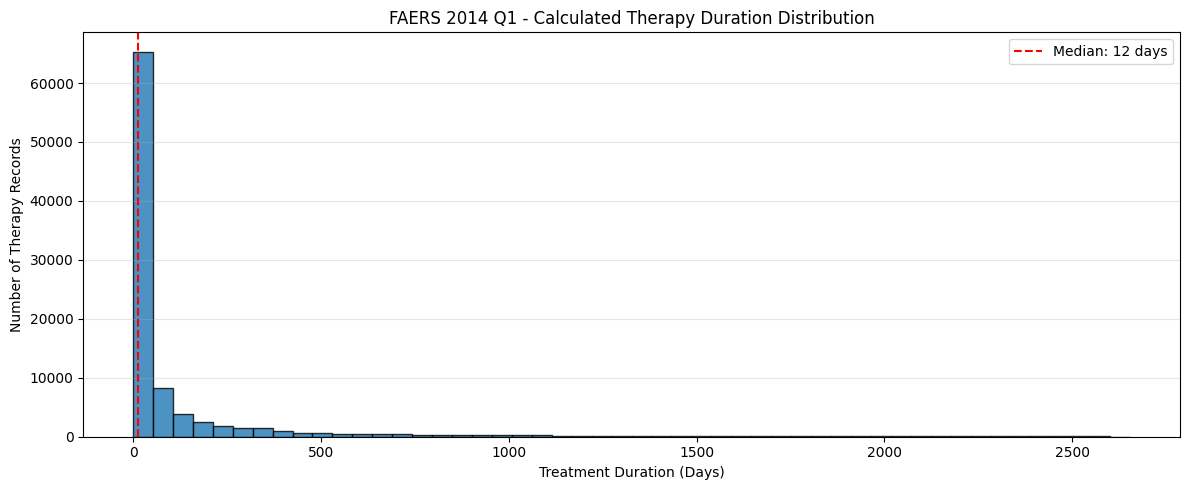

Median duration: 12.0
99th percentile: 2659.3900000000576
Records excluded from visualization: 948


In [75]:
import matplotlib.pyplot as plt

duration = ther_clean[
    "calculated_duration_days_clean"
].dropna()

upper_limit = duration.quantile(0.99)

plt.figure(figsize=(12, 5))

plt.hist(
    duration[duration <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    duration.median(),
    color="red",
    linestyle="--",
    label=f"Median: {duration.median():.0f} days"
)

plt.title(
    "FAERS 2014 Q1 - Calculated Therapy Duration Distribution"
)

plt.xlabel("Treatment Duration (Days)")
plt.ylabel("Number of Therapy Records")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Median duration:", duration.median())
print("99th percentile:", upper_limit)

print(
    "Records excluded from visualization:",
    (duration > upper_limit).sum()
)

Match primary suspect therapy record

In [77]:
ps_keys = pilot_drug_df[
    [
        "primaryid",
        "drug_seq"
    ]
].copy()

ps_keys = ps_keys.rename(
    columns={"drug_seq": "dsg_drug_seq"}
)

key_columns = ["primaryid", "dsg_drug_seq"]

for col in key_columns:
    ps_keys[col] = ps_keys[col].astype("string")
    ther_clean[col] = ther_clean[col].astype("string")

ps_keys = ps_keys.drop_duplicates()

ps_ther_df = ther_clean.merge(
    ps_keys,
    on=key_columns,
    how="inner",
    validate="many_to_one"
)

print("Matched PS therapy records:", len(ps_ther_df))

print(
    "Unique PS reports with therapy information:",
    ps_ther_df["primaryid"].nunique()
)

print(
    "PS therapy coverage:",
    round(
        ps_ther_df["primaryid"].nunique()
        / ps_keys["primaryid"].nunique() * 100,
        2
    ),
    "%"
)

print(
    "Repeated PS report-drug keys:",
    ps_ther_df.duplicated(
        subset=key_columns
    ).sum()
)

display(ps_ther_df.head())

Matched PS therapy records: 165563
Unique PS reports with therapy information: 159155
PS therapy coverage: 63.35 %
Repeated PS report-drug keys: 6408


,primaryid,caseid,dsg_drug_seq,start_dt,end_dt,dur,dur_cod,start_dt_precision,start_dt_clean,end_dt_precision,end_dt_clean,dur_numeric,dur_cod_clean,reported_duration_days,calculated_duration_days,invalid_date_sequence,reported_duration_days_invalid,reported_duration_days_clean,calculated_duration_days_invalid,calculated_duration_days_clean
0,100033001,10003300,1,20130913,NaN,NaN,NaN,DAY,2013-09-13,UNKNOWN,NaT,NaN,<NA>,NaN,NaN,0,0,NaN,0,NaN
1,100033061,10003306,1,20111014,NaN,NaN,NaN,DAY,2011-10-14,UNKNOWN,NaT,NaN,<NA>,NaN,NaN,0,0,NaN,0,NaN
2,100033072,10003307,1,20110510,NaN,NaN,NaN,DAY,2011-05-10,UNKNOWN,NaT,NaN,<NA>,NaN,NaN,0,0,NaN,0,NaN
3,100033082,10003308,1,20101122,NaN,NaN,NaN,DAY,2010-11-22,UNKNOWN,NaT,NaN,<NA>,NaN,NaN,0,0,NaN,0,NaN
4,100033092,10003309,1,20120427,NaN,NaN,NaN,DAY,2012-04-27,UNKNOWN,NaT,NaN,<NA>,NaN,NaN,0,0,NaN,0,NaN


In [78]:
therapy_counts = (
    ps_ther_df
    .groupby(["primaryid", "dsg_drug_seq"])
    .size()
)

print("Therapy records per primary suspect drug:")

display(therapy_counts.describe())

print(
    "PS drugs with multiple therapy records:",
    (therapy_counts > 1).sum()
)

print(
    "Maximum therapy records per PS drug:",
    therapy_counts.max()
)

print("\nTherapy record count distribution:")

display(
    therapy_counts.value_counts().sort_index().head(20)
)

Therapy records per primary suspect drug:


,0
count,159155.000000
mean,1.040263
std,0.298384
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,15.000000


PS drugs with multiple therapy records: 3892
Maximum therapy records per PS drug: 15

Therapy record count distribution:


,count
1,155263
2,2291
3,1004
4,399
5,133
6,40
7,14
8,5
9,3
12,1


In [80]:
therapy_features_df = (
    ps_ther_df
    .groupby(["primaryid", "dsg_drug_seq"])
    .agg(
        therapy_record_count=("primaryid", "size"),
        earliest_therapy_start=("start_dt_clean", "min"),
        latest_therapy_end=("end_dt_clean", "max"),
        max_calculated_duration_days=(
            "calculated_duration_days_clean", "max"
        ),
        max_reported_duration_days=(
            "reported_duration_days_clean", "max"
        )
    )
    .reset_index()
)

therapy_features_df["multiple_therapy_records"] = (
    therapy_features_df["therapy_record_count"] > 1
).astype(int)

therapy_features_df = therapy_features_df.rename(
    columns={"dsg_drug_seq": "drug_seq"}
)

print("Dataset shape:", therapy_features_df.shape)

print(
    "Duplicate report-drug keys:",
    therapy_features_df.duplicated(
        subset=["primaryid", "drug_seq"]
    ).sum()
)

display(therapy_features_df.head(10))

Dataset shape: (159155, 8)
Duplicate report-drug keys: 0


,primaryid,drug_seq,therapy_record_count,earliest_therapy_start,latest_therapy_end,max_calculated_duration_days,max_reported_duration_days,multiple_therapy_records
0,100033001,1,1,2013-09-13,NaT,NaN,NaN,0
1,100033061,1,1,2011-10-14,NaT,NaN,NaN,0
2,100033072,1,1,2011-05-10,NaT,NaN,NaN,0
3,100033082,1,1,2010-11-22,NaT,NaN,NaN,0
4,100033092,1,1,2012-04-27,NaT,NaN,NaN,0
5,100033102,1,1,2011-07-06,NaT,NaN,NaN,0
6,100033112,1,1,2010-08-11,2012-07-01,690.0,NaN,0
7,100033132,1,1,2010-10-21,NaT,NaN,NaN,0
8,100033141,1,1,2012-06-05,NaT,NaN,NaN,0
9,100033162,1,1,2012-02-07,NaT,NaN,NaN,0


In [81]:
therapy_columns = [
    "earliest_therapy_start",
    "latest_therapy_end",
    "max_calculated_duration_days",
    "max_reported_duration_days"
]

therapy_availability = pd.DataFrame({
    "available_count":
        therapy_features_df[therapy_columns].notna().sum(),

    "missing_count":
        therapy_features_df[therapy_columns].isna().sum(),

    "availability_percentage":
        therapy_features_df[therapy_columns]
        .notna().mean().mul(100).round(2)
})

display(therapy_availability)

,available_count,missing_count,availability_percentage
earliest_therapy_start,105750,53405,66.44
latest_therapy_end,48359,110796,30.38
max_calculated_duration_days,41455,117700,26.05
max_reported_duration_days,1270,157885,0.80


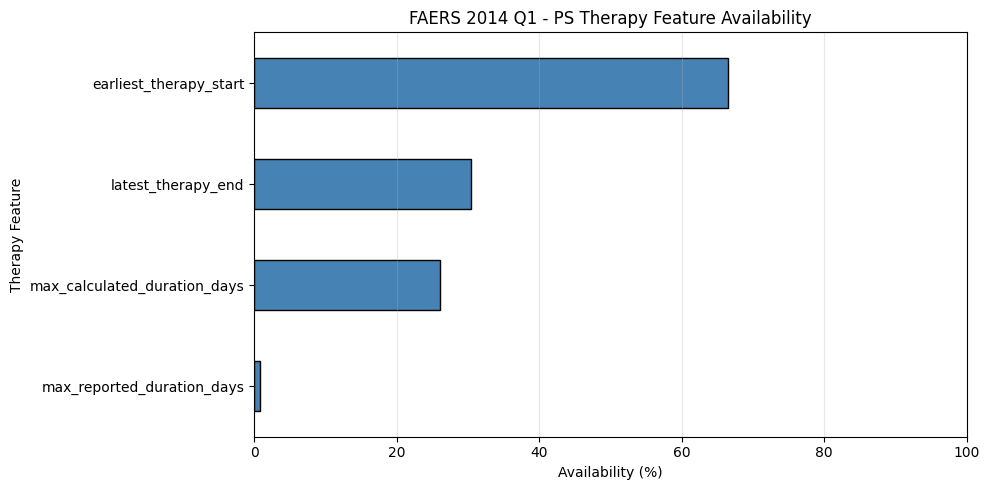

In [82]:
plt.figure(figsize=(10, 5))

therapy_availability[
    "availability_percentage"
].sort_values().plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title("FAERS 2014 Q1 - PS Therapy Feature Availability")
plt.xlabel("Availability (%)")
plt.ylabel("Therapy Feature")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Integration of Primary Suspect Therapy Features

Aggregated therapy features were integrated into
the AEOLUS-FAERS pilot dataset using the primary
report identifier and drug sequence.

A left join was performed to preserve all existing
reports, including those without therapy information.

Therapy-related features were retained for exploratory
analysis but excluded from the initial predictive
models due to missingness and potential temporal
data leakage.

In [84]:
merge_keys = ["primaryid", "drug_seq"]

for col in merge_keys:
    pilot_drug_df[col] = pilot_drug_df[col].astype("string")
    therapy_features_df[col] = (
        therapy_features_df[col].astype("string")
    )

original_row_count = len(pilot_drug_df)

integrated_ther_df = pilot_drug_df.merge(
    therapy_features_df,
    on=merge_keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Integrated dataset shape:", integrated_ther_df.shape)

print("\nMerge results:")
display(integrated_ther_df["_merge"].value_counts())

integrated_ther_df["therapy_record_available"] = (
    integrated_ther_df["_merge"] == "both"
).astype(int)

integrated_ther_df = integrated_ther_df.drop(
    columns=["_merge"]
)

assert len(integrated_ther_df) == original_row_count

print("Row count preserved:", len(integrated_ther_df))

print(
    "Therapy record coverage:",
    round(
        integrated_ther_df["therapy_record_available"]
        .mean() * 100, 2
    ),
    "%"
)

display(integrated_ther_df.head())

Integrated dataset shape: (251245, 42)

Merge results:


,count
_merge,
both,159155
left_only,92090
right_only,0


Row count preserved: 251245
Therapy record coverage: 63.35 %


,report_id,standard_concept_id,role_cod,provisional_hypersensitivity_label,primaryid,caseid,caseversion,age_years,age_missing,gender_clean,...,dose_missing,dose_freq_missing,high_medication_burden,therapy_record_count,earliest_therapy_start,latest_therapy_end,max_calculated_duration_days,max_reported_duration_days,multiple_therapy_records,therapy_record_available
0,PRIMARY_92198372,1110942,PS,0,92198372,9219837,2,NaN,1,Female,...,0,1,1,1.0,2011-05-26,NaT,NaN,NaN,0.0,1
1,PRIMARY_98124391,735843,PS,0,98124391,9812439,1,NaN,1,Female,...,0,0,0,1.0,2013-12-17,NaT,NaN,NaN,0.0,1
2,PRIMARY_98164081,917336,PS,0,98164081,9816408,1,18.0,0,Male,...,1,1,0,1.0,2013-08-09,NaT,NaN,NaN,0.0,1
3,PRIMARY_98972741,1397141,PS,0,98972741,9897274,1,NaN,1,Unknown,...,1,0,0,NaN,NaT,NaT,NaN,NaN,NaN,0
4,PRIMARY_100338831,723013,PS,0,100338831,10033883,1,50.0,0,Male,...,1,1,0,NaN,NaT,NaT,NaN,NaN,NaN,0


In [85]:
target = "provisional_hypersensitivity_label"

therapy_columns = [
    "therapy_record_count",
    "earliest_therapy_start",
    "latest_therapy_end",
    "max_calculated_duration_days",
    "max_reported_duration_days"
]

therapy_class_availability = (
    integrated_ther_df
    .groupby(target)[therapy_columns]
    .agg(lambda x: x.notna().mean() * 100)
    .T
)

therapy_class_availability.columns = [
    "Negative (%)",
    "Positive (%)"
]

therapy_class_availability["Difference (pp)"] = (
    therapy_class_availability["Positive (%)"]
    - therapy_class_availability["Negative (%)"]
)

display(therapy_class_availability.round(2))

,Negative (%),Positive (%),Difference (pp)
therapy_record_count,63.75,44.59,-19.16
earliest_therapy_start,42.32,31.62,-10.70
latest_therapy_end,19.24,19.62,0.38
max_calculated_duration_days,16.47,17.87,1.40
max_reported_duration_days,0.51,0.53,0.02


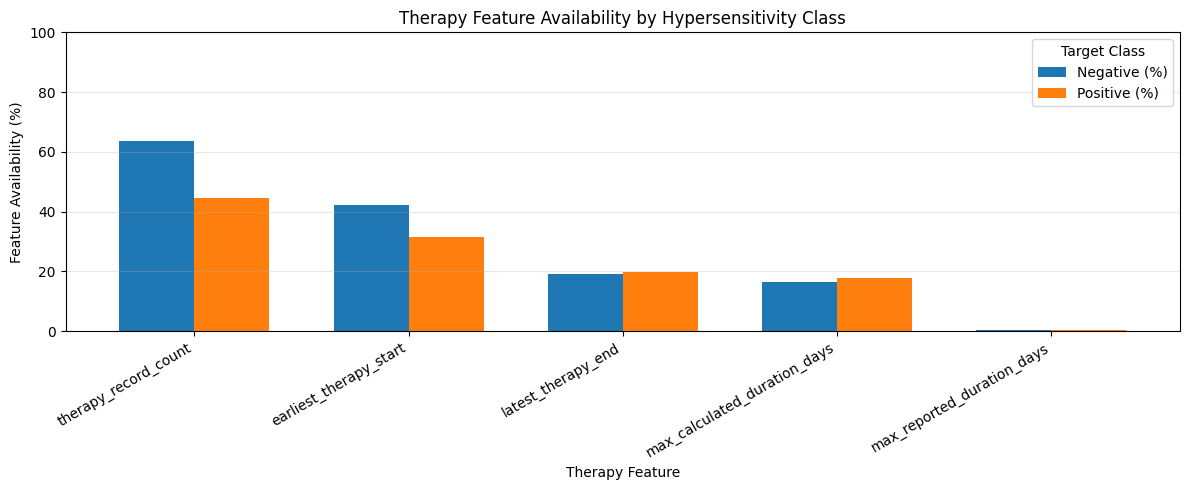

In [86]:
therapy_class_availability[
    ["Negative (%)", "Positive (%)"]
].plot(
    kind="bar",
    figsize=(12, 5),
    width=0.7
)

plt.title(
    "Therapy Feature Availability by Hypersensitivity Class"
)
plt.xlabel("Therapy Feature")
plt.ylabel("Feature Availability (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.legend(title="Target Class")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [87]:
import os

output_dir = "/content/drive/MyDrive/Capstone/faers_processed"

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "aeolus_faers_2014q1_pilot_with_therapy.csv"
)

integrated_ther_df.to_csv(output_path, index=False)

print("Dataset saved:", output_path)
print("Dataset shape:", integrated_ther_df.shape)

print(
    "File size:",
    round(os.path.getsize(output_path) / 1024**2, 2),
    "MB"
)

Dataset saved: /content/drive/MyDrive/Capstone/faers_processed/aeolus_faers_2014q1_pilot_with_therapy.csv
Dataset shape: (251245, 42)
File size: 42.64 MB


### Therapy Data Analysis Conclusion

Primary suspect therapy information was successfully
integrated into the AEOLUS-FAERS pilot dataset,
preserving all 251,245 reports.

Therapy information was available for 63.35% of
the integrated reports.

Substantial differences in therapy information
availability were observed between hypersensitivity
and non-hypersensitivity reports.

Due to high missingness, potential reporting bias,
and temporal data leakage, therapy-related features
were retained for exploratory analysis but excluded
from the initial predictive models.

## FAERS INDI - Treatment Indication Analysis

The INDI dataset contains reported medical
indications associated with drug administration.

The objective of this stage is to assess data
quality, identify indication patterns, and extract
relevant treatment indication features associated
with primary suspect drugs.

In [89]:
import pandas as pd
import os

indi_path = "/content/drive/MyDrive/Capstone/ascii/INDI14Q1.txt"

indi_df = pd.read_csv(
    indi_path,
    sep="$",
    dtype=str,
    encoding="latin-1"
)

indi_df.columns = (
    indi_df.columns.str.strip().str.lower()
)

print("Dataset shape:", indi_df.shape)
print("Available columns:", indi_df.columns.tolist())

display(indi_df.head(10))

Dataset shape: (581696, 4)
Available columns: ['primaryid', 'caseid', 'indi_drug_seq', 'indi_pt']


,primaryid,caseid,indi_drug_seq,indi_pt
0,100033001,10003300,1,Osteoporosis
1,100033011,10003301,1,Product used for unknown indication
2,100033061,10003306,1,Product used for unknown indication
3,100033072,10003307,1,Pulmonary hypertension
4,100033072,10003307,2,Connective tissue disorder
5,100033082,10003308,1,Pulmonary hypertension
6,100033082,10003308,2,Systemic sclerosis
7,100033092,10003309,1,Pulmonary hypertension
8,100033092,10003309,2,Sleep apnoea syndrome
9,100033102,10003310,1,Pulmonary arterial hypertension


Initial data quality assessment

In [90]:
print("Total indication records:", len(indi_df))

print(
    "Unique reports:",
    indi_df["primaryid"].nunique()
)

print(
    "Unique cases:",
    indi_df["caseid"].nunique()
)

print(
    "Unique indication terms:",
    indi_df["indi_pt"].nunique()
)

print(
    "Exact duplicate rows:",
    indi_df.duplicated().sum()
)

print(
    "Repeated report-drug keys:",
    indi_df.duplicated(
        subset=["primaryid", "indi_drug_seq"]
    ).sum()
)

print(
    "Duplicate report-drug-indication keys:",
    indi_df.duplicated(
        subset=[
            "primaryid",
            "indi_drug_seq",
            "indi_pt"
        ]
    ).sum()
)

Total indication records: 581696
Unique reports: 232392
Unique cases: 232392
Unique indication terms: 4657
Exact duplicate rows: 0
Repeated report-drug keys: 1998
Duplicate report-drug-indication keys: 0


In [91]:
indi_missing = pd.DataFrame({
    "available_count": indi_df.notna().sum(),
    "missing_count": indi_df.isna().sum(),
    "missing_percentage":
        indi_df.isna().mean().mul(100).round(2),
    "unique_values": indi_df.nunique()
}).sort_values(
    "missing_percentage",
    ascending=False
)

display(indi_missing)

,available_count,missing_count,missing_percentage,unique_values
primaryid,581696,0,0.0,232392
caseid,581696,0,0.0,232392
indi_drug_seq,581696,0,0.0,120
indi_pt,581696,0,0.0,4657


In [92]:
indi_clean = indi_df.copy()

indi_clean["indi_pt_normalized"] = (
    indi_clean["indi_pt"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
)

indi_clean["indi_pt_normalized"] = (
    indi_clean["indi_pt_normalized"]
    .replace("", pd.NA)
)

print(
    "Unique terms before normalization:",
    indi_df["indi_pt"].nunique()
)

print(
    "Unique terms after normalization:",
    indi_clean["indi_pt_normalized"].nunique()
)

print("\nTop 20 treatment indications:")

display(
    indi_clean["indi_pt_normalized"]
    .value_counts(dropna=False)
    .head(20)
)

Unique terms before normalization: 4657
Unique terms after normalization: 4657

Top 20 treatment indications:


,count
indi_pt_normalized,
PRODUCT USED FOR UNKNOWN INDICATION,167233
RHEUMATOID ARTHRITIS,27932
MULTIPLE SCLEROSIS,26638
CROHN'S DISEASE,14667
HYPERTENSION,14072
PERITONEAL DIALYSIS,11365
PSORIASIS,10241
PLASMA CELL MYELOMA,8618
PAIN,8527


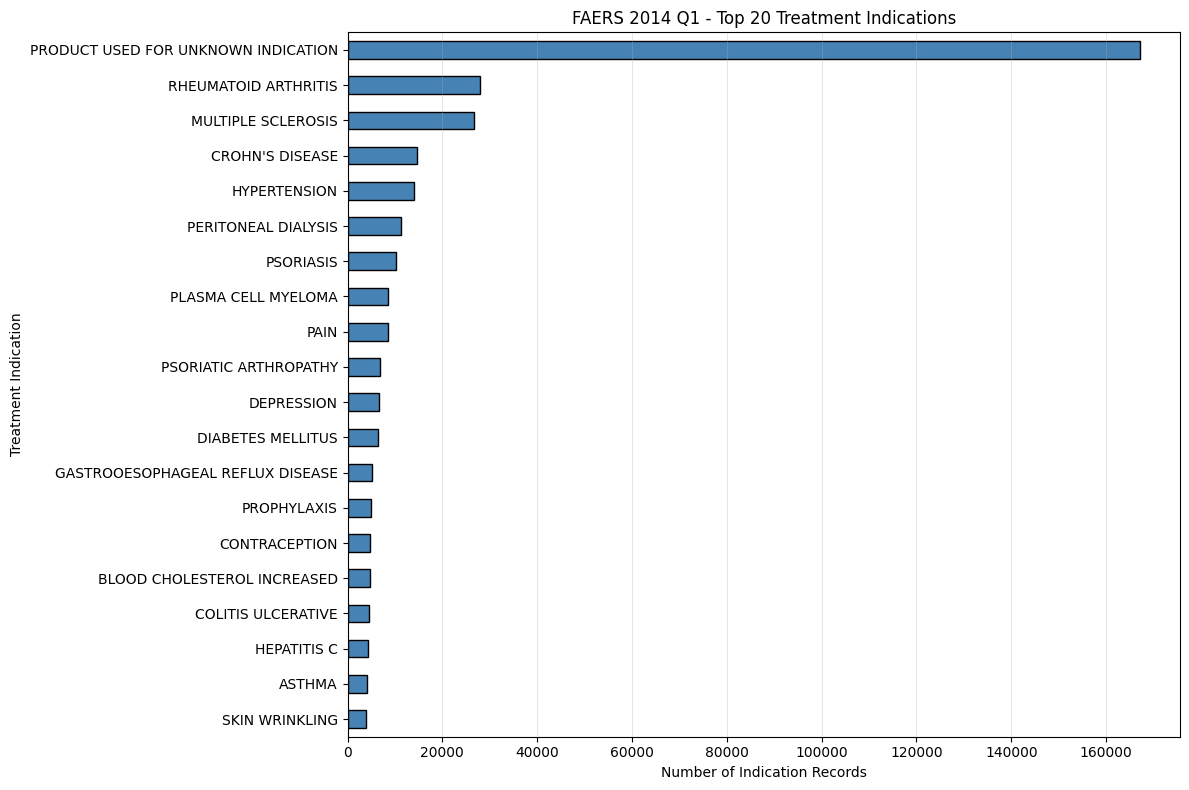

In [93]:
import matplotlib.pyplot as plt

top_indications = (
    indi_clean["indi_pt_normalized"]
    .value_counts()
    .head(20)
    .sort_values()
)

plt.figure(figsize=(12, 8))

top_indications.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title("FAERS 2014 Q1 - Top 20 Treatment Indications")
plt.xlabel("Number of Indication Records")
plt.ylabel("Treatment Indication")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
unknown_pattern = (
    r"UNKNOWN|UNSPECIFIED|NOT SPECIFIED|"
    r"NOT REPORTED|NOT AVAILABLE|NOT PROVIDED"
)

unknown_candidates = indi_clean[
    indi_clean["indi_pt_normalized"].str.contains(
        unknown_pattern,
        regex=True,
        na=False
    )
]

print("Potential unknown indication records:",
      len(unknown_candidates))

print("Unique candidate terms:",
      unknown_candidates["indi_pt_normalized"].nunique())

display(
    unknown_candidates["indi_pt_normalized"]
    .value_counts()
    .to_frame("count")
)

Potential unknown indication records: 167753
Unique candidate terms: 16


,count
indi_pt_normalized,
PRODUCT USED FOR UNKNOWN INDICATION,167233
MATERNAL EXPOSURE TIMING UNSPECIFIED,343
LUNG CARCINOMA CELL TYPE UNSPECIFIED STAGE 0,34
PERIPHERAL T-CELL LYMPHOMA UNSPECIFIED,32
NON-HODGKIN'S LYMPHOMA UNSPECIFIED HISTOLOGY INDOLENT,30
LUNG CARCINOMA CELL TYPE UNSPECIFIED STAGE IV,22
TONGUE NEOPLASM MALIGNANT STAGE UNSPECIFIED,14
"DELUSIONAL DISORDER, UNSPECIFIED TYPE",9
FOETAL EXPOSURE TIMING UNSPECIFIED,8


In [95]:
hypersensitivity_pattern = (
    r"ALLERG|HYPERSENSITIV|ANAPHYLA|"
    r"URTICARIA|ANGIOEDEMA"
)

potential_leakage_indi = indi_clean[
    indi_clean["indi_pt_normalized"].str.contains(
        hypersensitivity_pattern,
        regex=True,
        na=False
    )
]

print("Potential leakage indication records:",
      len(potential_leakage_indi))

print("Unique reports:",
      potential_leakage_indi["primaryid"].nunique())

print("Unique indication terms:",
      potential_leakage_indi["indi_pt_normalized"].nunique())

display(
    potential_leakage_indi["indi_pt_normalized"]
    .value_counts()
    .to_frame("count")
)

Potential leakage indication records: 3983
Unique reports: 2854
Unique indication terms: 46


,count
indi_pt_normalized,
HYPERSENSITIVITY,1926
SEASONAL ALLERGY,556
MULTIPLE ALLERGIES,242
HEREDITARY ANGIOEDEMA,208
RHINITIS ALLERGIC,149
URTICARIA CHRONIC,147
ANGIOEDEMA,144
URTICARIA,134
CHRONIC SPONTANEOUS URTICARIA,75


In [97]:
pilot_ps_keys = pilot_drug_df[
    ["primaryid", "drug_seq"]
].copy()

pilot_ps_keys["primaryid"] = (
    pilot_ps_keys["primaryid"].astype("string")
)

pilot_ps_keys["drug_seq"] = (
    pilot_ps_keys["drug_seq"].astype("string")
)

indi_clean["primaryid"] = (
    indi_clean["primaryid"].astype("string")
)

indi_clean["indi_drug_seq"] = (
    indi_clean["indi_drug_seq"].astype("string")
)

assert not pilot_ps_keys.duplicated().any()

ps_indi_df = indi_clean.merge(
    pilot_ps_keys,
    left_on=["primaryid", "indi_drug_seq"],
    right_on=["primaryid", "drug_seq"],
    how="inner",
    validate="many_to_one"
)

print("Matching PS indication records:",
      len(ps_indi_df))

print("Unique matching PS reports:",
      ps_indi_df["primaryid"].nunique())

print("Unique PS indication terms:",
      ps_indi_df["indi_pt_normalized"].nunique())

print(
    "PS indication coverage:",
    round(
        ps_indi_df["primaryid"].nunique()
        / len(pilot_ps_keys) * 100, 2
    ),
    "%"
)

display(ps_indi_df.head(10))

Matching PS indication records: 223863
Unique matching PS reports: 222317
Unique PS indication terms: 3300
PS indication coverage: 88.49 %


,primaryid,caseid,indi_drug_seq,indi_pt,indi_pt_normalized,drug_seq
0,100033001,10003300,1,Osteoporosis,OSTEOPOROSIS,1
1,100033011,10003301,1,Product used for unknown indication,PRODUCT USED FOR UNKNOWN INDICATION,1
2,100033061,10003306,1,Product used for unknown indication,PRODUCT USED FOR UNKNOWN INDICATION,1
3,100033072,10003307,1,Pulmonary hypertension,PULMONARY HYPERTENSION,1
4,100033082,10003308,1,Pulmonary hypertension,PULMONARY HYPERTENSION,1
5,100033092,10003309,1,Pulmonary hypertension,PULMONARY HYPERTENSION,1
6,100033102,10003310,1,Pulmonary arterial hypertension,PULMONARY ARTERIAL HYPERTENSION,1
7,100033112,10003311,1,Pulmonary hypertension,PULMONARY HYPERTENSION,1
8,100033132,10003313,1,Pulmonary hypertension,PULMONARY HYPERTENSION,1
9,100033141,10003314,1,Product used for unknown indication,PRODUCT USED FOR UNKNOWN INDICATION,1


In [98]:
indications_per_drug = (
    ps_indi_df
    .groupby(["primaryid", "drug_seq"])
    ["indi_pt_normalized"]
    .nunique()
)

print("Indication count statistics:")

display(indications_per_drug.describe())

print(
    "PS drugs with multiple indications:",
    (indications_per_drug > 1).sum()
)

print(
    "Maximum indications per PS drug:",
    indications_per_drug.max()
)

print("\nTop 20 PS drug indications:")

display(
    ps_indi_df["indi_pt_normalized"]
    .value_counts()
    .head(20)
)

Indication count statistics:


,indi_pt_normalized
count,222317.000000
mean,1.006954
std,0.092136
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,5.000000


PS drugs with multiple indications: 1390
Maximum indications per PS drug: 5

Top 20 PS drug indications:


,count
indi_pt_normalized,
PRODUCT USED FOR UNKNOWN INDICATION,36371
RHEUMATOID ARTHRITIS,20226
MULTIPLE SCLEROSIS,16505
CROHN'S DISEASE,10473
PSORIASIS,7948
PLASMA CELL MYELOMA,6941
PERITONEAL DIALYSIS,5222
PSORIATIC ARTHROPATHY,5088
CONTRACEPTION,3511


In [99]:
unknown_indication_terms = {
    "PRODUCT USED FOR UNKNOWN INDICATION"
}

leakage_indication_terms = set(
    potential_leakage_indi["indi_pt_normalized"].unique()
)

ps_indi_df = ps_indi_df.copy()

ps_indi_df["unknown_indication"] = (
    ps_indi_df["indi_pt_normalized"]
    .isin(unknown_indication_terms)
    .astype(int)
)

ps_indi_df["potential_leakage"] = (
    ps_indi_df["indi_pt_normalized"]
    .isin(leakage_indication_terms)
    .astype(int)
)

ps_indi_df["usable_indication"] = (
    (ps_indi_df["unknown_indication"] == 0) &
    (ps_indi_df["potential_leakage"] == 0)
).astype(int)

print("Total PS indication records:", len(ps_indi_df))

print("Unknown indication records:",
      ps_indi_df["unknown_indication"].sum())

print("Potential leakage records:",
      ps_indi_df["potential_leakage"].sum())

print("Usable indication records:",
      ps_indi_df["usable_indication"].sum())

print("Unique usable indication terms:",
      ps_indi_df.loc[
          ps_indi_df["usable_indication"] == 1,
          "indi_pt_normalized"
      ].nunique())

Total PS indication records: 223863
Unknown indication records: 36371
Potential leakage records: 757
Usable indication records: 186735
Unique usable indication terms: 3267


In [100]:
indication_features = (
    ps_indi_df
    .groupby(["primaryid", "drug_seq"])
    .agg(
        indication_count=(
            "indi_pt_normalized", "nunique"
        ),
        unknown_indication_flag=(
            "unknown_indication", "max"
        ),
        potential_leakage_indication_flag=(
            "potential_leakage", "max"
        ),
        usable_indication_count=(
            "usable_indication", "sum"
        )
    )
    .reset_index()
)

usable_terms = (
    ps_indi_df[
        ps_indi_df["usable_indication"] == 1
    ]
    .groupby(["primaryid", "drug_seq"])
    ["indi_pt_normalized"]
    .apply(lambda x: "|".join(sorted(set(x))))
    .reset_index(name="indication_terms")
)

indication_features = indication_features.merge(
    usable_terms,
    on=["primaryid", "drug_seq"],
    how="left",
    validate="one_to_one"
)

indication_features["indication_record_available"] = 1

print("Dataset shape:", indication_features.shape)

print(
    "Duplicate report-drug keys:",
    indication_features.duplicated(
        ["primaryid", "drug_seq"]
    ).sum()
)

display(indication_features.head(10))

Dataset shape: (222317, 8)
Duplicate report-drug keys: 0


,primaryid,drug_seq,indication_count,unknown_indication_flag,potential_leakage_indication_flag,usable_indication_count,indication_terms,indication_record_available
0,100033001,1,1,0,0,1,OSTEOPOROSIS,1
1,100033011,1,1,1,0,0,NaN,1
2,100033061,1,1,1,0,0,NaN,1
3,100033072,1,1,0,0,1,PULMONARY HYPERTENSION,1
4,100033082,1,1,0,0,1,PULMONARY HYPERTENSION,1
5,100033092,1,1,0,0,1,PULMONARY HYPERTENSION,1
6,100033102,1,1,0,0,1,PULMONARY ARTERIAL HYPERTENSION,1
7,100033112,1,1,0,0,1,PULMONARY HYPERTENSION,1
8,100033132,1,1,0,0,1,PULMONARY HYPERTENSION,1
9,100033141,1,1,1,0,0,NaN,1


In [102]:
pilot_drug_df["primaryid"] = (
    pilot_drug_df["primaryid"].astype("string")
)

pilot_drug_df["drug_seq"] = (
    pilot_drug_df["drug_seq"].astype("string")
)

indication_features["primaryid"] = (
    indication_features["primaryid"].astype("string")
)

indication_features["drug_seq"] = (
    indication_features["drug_seq"].astype("string")
)

original_row_count = len(pilot_drug_df)

pilot_drug_df = pilot_drug_df.merge(
    indication_features,
    on=["primaryid", "drug_seq"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Merge results:")
display(pilot_drug_df["_merge"].value_counts())

pilot_drug_df.drop(columns="_merge", inplace=True)

count_flag_columns = [
    "indication_count",
    "unknown_indication_flag",
    "potential_leakage_indication_flag",
    "usable_indication_count",
    "indication_record_available"
]

for col in count_flag_columns:
    pilot_drug_df[col] = (
        pilot_drug_df[col].fillna(0).astype(int)
    )

pilot_drug_df["usable_indication_available"] = (
    pilot_drug_df["usable_indication_count"] > 0
).astype(int)

assert len(pilot_drug_df) == original_row_count

integrated_df = pilot_drug_df

print("Updated dataset shape:", integrated_df.shape)

display(
    integrated_df[
        ["primaryid", "drug_seq"] +
        count_flag_columns +
        ["indication_terms", "usable_indication_available"]
    ].head(10)
)

Merge results:


,count
_merge,
both,222317
left_only,28928
right_only,0


Updated dataset shape: (251245, 42)


,primaryid,drug_seq,indication_count,unknown_indication_flag,potential_leakage_indication_flag,usable_indication_count,indication_record_available,indication_terms,usable_indication_available
0,92198372,1,1,0,0,1,1,ASTHMA,1
1,98124391,1,1,0,0,1,1,MULTIPLE SCLEROSIS,1
2,98164081,1,0,0,0,0,0,NaN,0
3,98972741,1,1,0,0,1,1,GLIOBLASTOMA MULTIFORME,1
4,100338831,1,1,1,0,0,1,NaN,0
5,99801681,1,1,0,0,1,1,PSORIATIC ARTHROPATHY,1
6,99110562,1,1,0,0,1,1,PULMONARY HYPERTENSION,1
7,63758494,1,1,0,0,1,1,BRONCHIOLOALVEOLAR CARCINOMA,1
8,100176941,1,0,0,0,0,0,NaN,0
9,99185481,1,1,0,0,1,1,MULTIPLE SCLEROSIS,1


In [103]:
target = "provisional_hypersensitivity_label"

availability_columns = [
    "indication_record_available",
    "usable_indication_available",
    "unknown_indication_flag",
    "potential_leakage_indication_flag"
]

availability_summary = (
    integrated_df
    .groupby(target)[availability_columns]
    .mean()
    .T * 100
)

availability_summary.columns = [
    "Negative (%)", "Positive (%)"
]

availability_summary["Difference (pp)"] = (
    availability_summary["Positive (%)"] -
    availability_summary["Negative (%)"]
)

display(availability_summary.round(2))

,Negative (%),Positive (%),Difference (pp)
indication_record_available,89.04,62.96,-26.08
usable_indication_available,74.24,49.83,-24.41
unknown_indication_flag,14.52,12.52,-2.00
potential_leakage_indication_flag,0.29,0.68,0.38


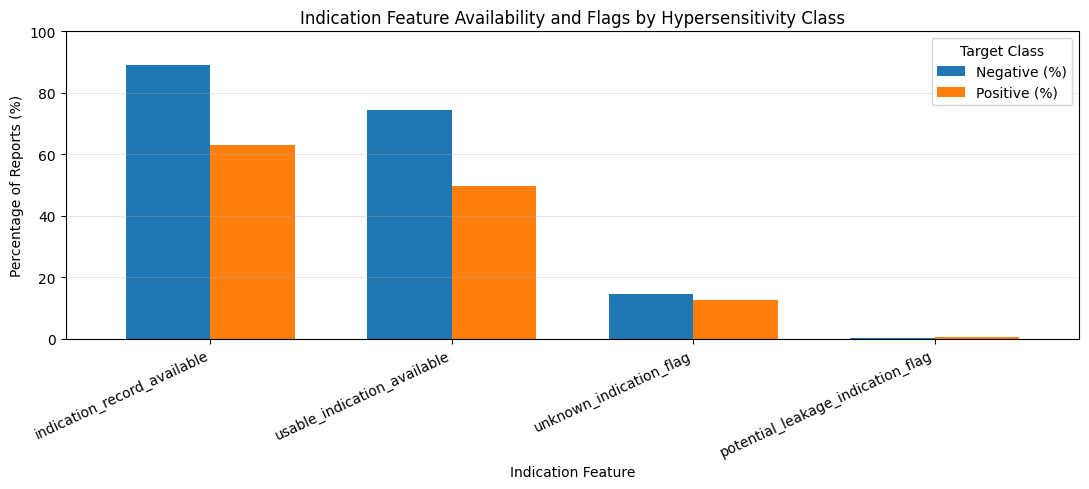

In [104]:
import matplotlib.pyplot as plt

ax = availability_summary[
    ["Negative (%)", "Positive (%)"]
].plot(
    kind="bar",
    figsize=(11, 5),
    width=0.7
)

plt.title(
    "Indication Feature Availability and Flags "
    "by Hypersensitivity Class"
)

plt.ylabel("Percentage of Reports (%)")
plt.xlabel("Indication Feature")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Target Class")
plt.tight_layout()
plt.show()

In [105]:
print("Dataset shape:", integrated_df.shape)

for i, col in enumerate(integrated_df.columns, 1):
    print(i, col)

Dataset shape: (251245, 42)
1 report_id
2 standard_concept_id
3 role_cod
4 provisional_hypersensitivity_label
5 primaryid
6 caseid
7 caseversion
8 age_years
9 age_missing
10 gender_clean
11 gender_missing
12 weight_kg
13 weight_missing
14 reporter_country_clean
15 occr_country_clean
16 event_dt
17 init_fda_dt
18 fda_dt
19 drug_seq
20 drugname_clean
21 route_clean
22 dose_form_clean
23 dose_freq_clean
24 dose_unit_clean
25 dose_mg
26 total_drug_count
27 primary_suspect_count
28 secondary_suspect_count
29 concomitant_drug_count
30 interacting_drug_count
31 route_missing
32 dose_form_missing
33 dose_missing
34 dose_freq_missing
35 high_medication_burden
36 indication_count
37 unknown_indication_flag
38 potential_leakage_indication_flag
39 usable_indication_count
40 indication_terms
41 indication_record_available
42 usable_indication_available


In [106]:
ther_features = [
    "therapy_record_count",
    "earliest_therapy_start",
    "latest_therapy_end",
    "max_calculated_duration_days",
    "max_reported_duration_days",
    "multiple_therapy_records",
    "therapy_record_available"
]

indi_features = [
    "indication_count",
    "unknown_indication_flag",
    "potential_leakage_indication_flag",
    "usable_indication_count",
    "indication_record_available",
    "indication_terms",
    "usable_indication_available"
]

for group, columns in {
    "THER": ther_features,
    "INDI": indi_features
}.items():

    print(f"\n{group} feature verification:")

    for col in columns:
        print(
            col,
            "Available" if col in integrated_df.columns
            else "MISSING"
        )


THER feature verification:
therapy_record_count MISSING
earliest_therapy_start MISSING
latest_therapy_end MISSING
max_calculated_duration_days MISSING
max_reported_duration_days MISSING
multiple_therapy_records MISSING
therapy_record_available MISSING

INDI feature verification:
indication_count Available
unknown_indication_flag Available
potential_leakage_indication_flag Available
usable_indication_count Available
indication_record_available Available
indication_terms Available
usable_indication_available Available


In [108]:
print("Therapy dataset shape:", therapy_features_df.shape)

print("\nAvailable columns:")
print(therapy_features_df.columns.tolist())

print(
    "\nDuplicate report-drug keys:",
    therapy_features_df.duplicated(
        ["primaryid", "drug_seq"]
    ).sum()
)

display(therapy_features_df.head())

Therapy dataset shape: (159155, 8)

Available columns:
['primaryid', 'drug_seq', 'therapy_record_count', 'earliest_therapy_start', 'latest_therapy_end', 'max_calculated_duration_days', 'max_reported_duration_days', 'multiple_therapy_records']

Duplicate report-drug keys: 0


,primaryid,drug_seq,therapy_record_count,earliest_therapy_start,latest_therapy_end,max_calculated_duration_days,max_reported_duration_days,multiple_therapy_records
0,100033001,1,1,2013-09-13,NaT,NaN,NaN,0
1,100033061,1,1,2011-10-14,NaT,NaN,NaN,0
2,100033072,1,1,2011-05-10,NaT,NaN,NaN,0
3,100033082,1,1,2010-11-22,NaT,NaN,NaN,0
4,100033092,1,1,2012-04-27,NaT,NaN,NaN,0


In [110]:
integrated_df["primaryid"] = (
    integrated_df["primaryid"].astype("string")
)

integrated_df["drug_seq"] = (
    integrated_df["drug_seq"].astype("string")
)

therapy_features_df["primaryid"] = (
    therapy_features_df["primaryid"].astype("string")
)

therapy_features_df["drug_seq"] = (
    therapy_features_df["drug_seq"].astype("string")
)

original_row_count = len(integrated_df)

integrated_df = integrated_df.merge(
    therapy_features_df,
    on=["primaryid", "drug_seq"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("Merge results:")
display(integrated_df["_merge"].value_counts())

integrated_df["therapy_record_available"] = (
    integrated_df["_merge"] == "both"
).astype(int)

integrated_df.drop(columns="_merge", inplace=True)

assert len(integrated_df) == original_row_count
assert integrated_df["report_id"].is_unique

print("Updated dataset shape:", integrated_df.shape)

print(
    "Therapy coverage:",
    round(
        integrated_df["therapy_record_available"].mean() * 100,
        2
    ),
    "%"
)

Merge results:


,count
_merge,
both,159155
left_only,92090
right_only,0


Updated dataset shape: (251245, 49)
Therapy coverage: 63.35 %


In [111]:
target = "provisional_hypersensitivity_label"

print("Dataset shape:", integrated_df.shape)

print("Unique reports:",
      integrated_df["report_id"].nunique())

print("Unique cases:",
      integrated_df["caseid"].nunique())

print("Unique drug concepts:",
      integrated_df["standard_concept_id"].nunique())

print("Duplicate rows:",
      integrated_df.duplicated().sum())

print("Duplicate report IDs:",
      integrated_df["report_id"].duplicated().sum())

print("Missing target values:",
      integrated_df[target].isna().sum())

print("\nTarget distribution:")

display(
    integrated_df[target]
    .value_counts()
    .to_frame("count")
)

assert len(integrated_df) == 251245
assert integrated_df.shape[1] == 49
assert integrated_df["report_id"].is_unique
assert integrated_df[target].notna().all()
assert integrated_df[target].sum() == 5326

Dataset shape: (251245, 49)
Unique reports: 251245
Unique cases: 251245
Unique drug concepts: 1331
Duplicate rows: 0
Duplicate report IDs: 0
Missing target values: 0

Target distribution:


,count
provisional_hypersensitivity_label,
0,245919
1,5326


In [112]:
feature_summary = pd.DataFrame({
    "data_type": integrated_df.dtypes.astype(str),
    "available_count": integrated_df.notna().sum(),
    "missing_count": integrated_df.isna().sum(),
    "missing_percentage": (
        integrated_df.isna().mean() * 100
    ).round(2),
    "unique_values": integrated_df.nunique()
})

feature_summary = feature_summary.sort_values(
    "missing_percentage",
    ascending=False
)

display(feature_summary)

,data_type,available_count,missing_count,missing_percentage,unique_values
max_reported_duration_days,float64,1270,249975,99.49,160
max_calculated_duration_days,float64,41455,209790,83.50,2473
latest_therapy_end,datetime64[ns],48359,202886,80.75,3193
weight_kg,float64,54501,196744,78.31,3429
earliest_therapy_start,datetime64[ns],105750,145495,57.91,4700
dose_freq_clean,string,113971,137274,54.64,67
dose_mg,float64,134220,117025,46.58,1388
event_dt,object,141773,109472,43.57,3666
dose_unit_clean,string,148583,102662,40.86,65
therapy_record_count,float64,159155,92090,36.65,12


In [113]:
import os

output_dir = "/content/drive/MyDrive/integrated_processed"

os.makedirs(output_dir, exist_ok=True)

output_path = os.path.join(
    output_dir,
    "aeolus_faers_2014q1_integrated_pilot.csv"
)

integrated_df.to_csv(output_path, index=False)

feature_summary.to_csv(
    os.path.join(
        output_dir,
        "pilot_feature_summary.csv"
    )
)

print("Integrated pilot dataset saved.")
print("Dataset shape:", integrated_df.shape)

print(
    "File size:",
    round(os.path.getsize(output_path) / (1024**2), 2),
    "MB"
)

print("Saved location:", output_path)

Integrated pilot dataset saved.
Dataset shape: (251245, 49)
File size: 49.06 MB
Saved location: /content/drive/MyDrive/integrated_processed/aeolus_faers_2014q1_integrated_pilot.csv
